# 05 — Bespoke Conventional Performance CNN

Run augmented tanh first, then the five augmented ReLU learning rates, serially. Eleven fixed views per training original; no weight decay. Matching saved runs are explicitly reused by default with their scores and IDs. Set `FRESH_RUNS = True` for new groups on a future manual run. This notebook has not been executed.


In [1]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from scripts.model import digit_experiment_helpers as experiments


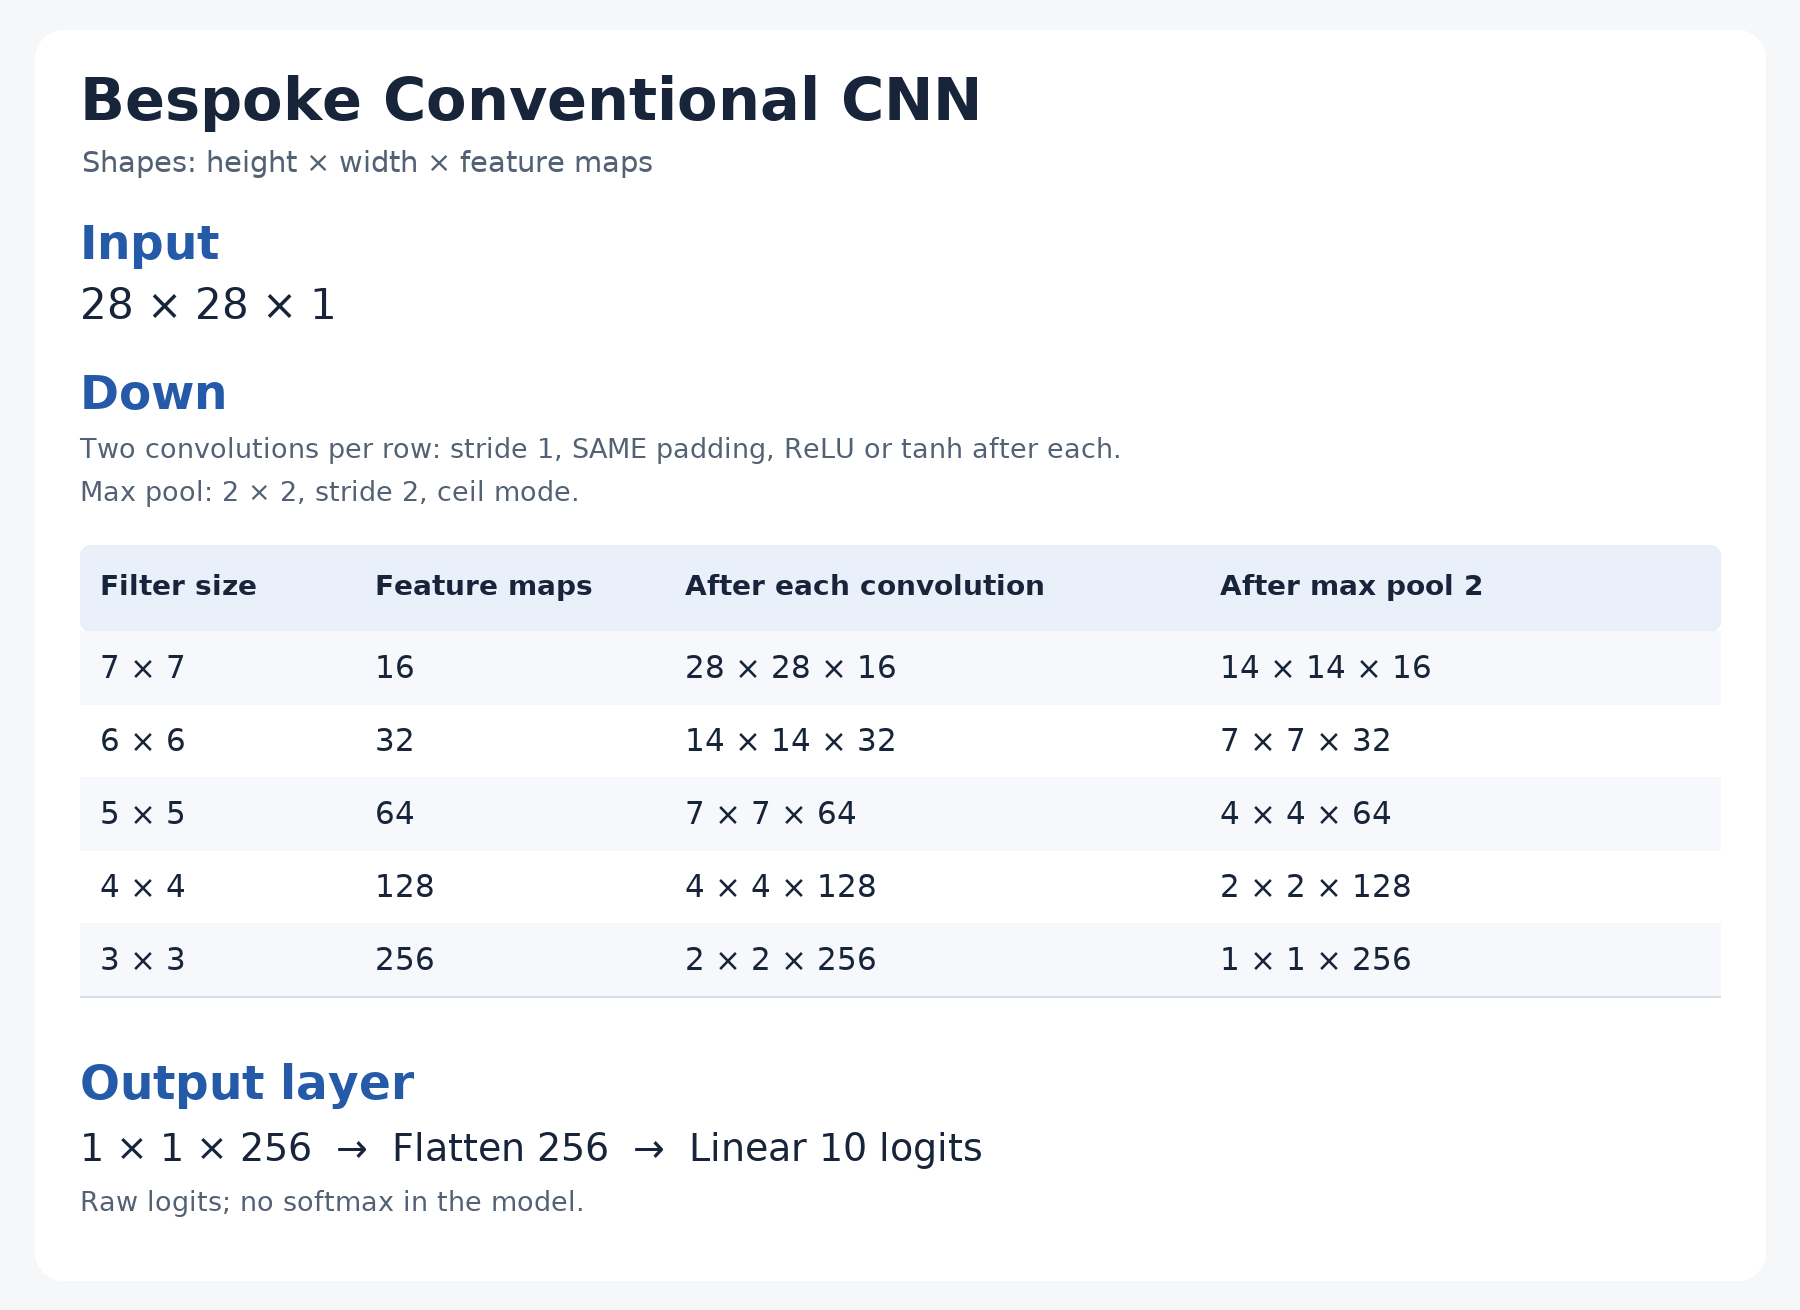

In [2]:
display(Image(filename=str(project_root / "docs/evaluations/assets/bespoke-conventional-architecture.png"), width=480))


## Experiment settings


In [3]:
MODEL_NAME = "bespoke28"
TANH_RATE = 1e-4
RELU_RATES = (0.0005, 0.00075, 0.001, 0.00125, 0.0015)
EPOCHS = 3
WARMUP_FRACTION = 0.10
WEIGHT_DECAY = 0.0
ROTATION_ANGLES = (0, -5, 5, -10, 10, -22, 22, -45, 45, -90, 90)
AUGMENTATION_SEED = 42
ROTATION_INTERPOLATION = "bilinear"
ROTATION_FILL = 0.0
SEED = 42
BATCH_SIZE = 64
VALIDATION_FRACTION = 0.2
FRESH_RUNS = False
SAVED_GROUPS = tuple(project_root / "data/experiments" / name for name in (
    "bespoke_lr_sweep_20261030_142313_4cfd332a",  # Augmented tanh.
    "bespoke_lr_sweep_20261030_143049_e5322aac",  # Augmented ReLU center.
    "bespoke_lr_sweep_20261030_143704_01fa13bf",  # Four finer ReLU rates.
))
SELECTED_RUNS = []


## Inspect data and model


In [4]:
experiments.show_dataset_summary()
experiments.inspect_bespoke_model(activation="tanh", seed=SEED, model_name=MODEL_NAME)


Training shape: (42000, 785)
Test shape: (28000, 784)
BespokeCNN28: activation=tanh, input=(1, 1, 28, 28)
Output shape: (1, 10)


/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


## Train only when ready

Split first: 33,600 training originals, 8,400 unchanged upright validation images. Each original contributes 0°, ±5°, ±10°, ±22°, ±45° and ±90° views, lazily generated about the pixel-grid center using bilinear interpolation and black fill. No uniform random angles or eleven stored datasets. Labels are retained; large rotations may make some digits ambiguous or crop strokes.

369,600 logical training examples per epoch; batch 64 gives 5,775 updates per epoch and 17,325 over three epochs. Linear warm-up reaches target at update 1,733 then holds. This is 11× the original three-epoch update budget. Compare with the saved conventional tanh LR1e-4 baseline (97.26%); do not retrain it. The next cell visits tanh first, then ReLU rates in listed order. Matching completed runs are reused with scores/IDs; missing configurations train serially. FRESH_RUNS=True allocates new groups for every configuration. Do not execute it while another managed experiment is active.


In [5]:
assert MODEL_NAME == "bespoke28"
assert SEED == 42 and BATCH_SIZE == 64 and VALIDATION_FRACTION == 0.2
assert ROTATION_INTERPOLATION == "bilinear" and ROTATION_FILL == 0.0
assert WEIGHT_DECAY == 0.0
SELECTED_RUNS = experiments.run_augmented_comparison(
    tanh_rate=TANH_RATE, relu_rates=RELU_RATES, rotation_angles=ROTATION_ANGLES,
    epochs=EPOCHS, warmup_fraction=WARMUP_FRACTION, weight_decay=WEIGHT_DECAY,
    augmentation_seed=AUGMENTATION_SEED, saved_groups=SAVED_GROUPS, fresh=FRESH_RUNS,
)


Already completed, no retraining | tanh | target_lr=0.0001 | validation_accuracy=98.68% | 20261030_142314_039b2794
Already completed, no retraining | relu | target_lr=0.0005 | validation_accuracy=99.04% | 20261030_143705_1077c38e
Already completed, no retraining | relu | target_lr=0.00075 | validation_accuracy=99.14% | 20261030_143937_9823b3b6
Already completed, no retraining | relu | target_lr=0.001 | validation_accuracy=98.76% | 20261030_143050_495b4a16
Already completed, no retraining | relu | target_lr=0.00125 | validation_accuracy=98.73% | 20261030_144207_b32afc08
Already completed, no retraining | relu | target_lr=0.0015 | validation_accuracy=98.56% | 20261030_144437_09ca63e5


## Follow-up: best ReLU settings for ten epochs

Fresh initialization at the best tested rate, 0.00075; ten epochs, same eleven fixed views and zero weight decay. This is a new run, not continuation of the three-epoch checkpoint. 57,750 optimizer updates; 10% warm-up now lasts 5,775 updates (the first full expanded epoch), then holds. Its first three epochs do not reproduce the shorter run’s 1,733-step warm-up. The cell below deliberately starts a fresh group when executed, unless a matching ten-epoch group is selected for reuse.


In [6]:
BEST_RELU_RATE = 0.00075
FOLLOWUP_EPOCHS = 10
FOLLOWUP_DIRECTORY = None  # Select a saved ten-epoch group to reuse; None starts fresh.


In [7]:
FOLLOWUP_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=FOLLOWUP_EPOCHS, learning_rates=(BEST_RELU_RATE,),
    warmup_fraction=WARMUP_FRACTION, weight_decay=WEIGHT_DECAY,
    model_name=MODEL_NAME, activations=("relu",), rotation_angles=ROTATION_ANGLES,
    augmentation_seed=AUGMENTATION_SEED, sweep_directory=FOLLOWUP_DIRECTORY,
)


Learning-rate testing results: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/experiments/bespoke_lr_sweep_20261030_165356_eff04a49

START 20261030_165357_fab04b1d | relu | target_lr=0.00075 | 10 epochs | warmup=5775/57750 steps
Training device: mps
/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(
Epoch 01/10 | train loss 0.6504, accuracy 76.63% | val loss 0.0594, accuracy 98.31%
Epoch 02/10 | train loss 0.0894, accuracy 97.43% | val loss 0.0519, accuracy 98.61%
Epoch 03/10 | train loss 0.0584, accuracy 98.34% | val loss 0.0399, accuracy 98.99%
Epoch 04/10 | train loss 0.0455, accuracy 98.69% | val loss 0.0451, accuracy 99.04%
Epoch 05/10 | train loss 0.0380, acc

## 4. L2 only — ten fresh epochs

Initial untuned strengths: explicit L2 λ=1e-05; decoupled decay=0. L2 is `(λ/2) × sum(weight²)`, applied to mean training cross-entropy. Both treatments include named weight tensors and exclude biases. Adam for L2-only; AdamW for decoupled-decay arms. Training data loss and total L2-penalized objective are reported separately; validation remains unpenalized cross-entropy. Same ReLU LR0.00075, eleven views, fresh initialization and 5,775/57,750-step warm-up.


In [8]:
SECTION_4_DIRECTORY = None  # Select a matching saved group for reuse; None allocates a fresh run.
SECTION_4_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=10, learning_rates=(BEST_RELU_RATE,), warmup_fraction=WARMUP_FRACTION,
    weight_decay=0.0, model_name=MODEL_NAME, activations=("relu",),
    rotation_angles=ROTATION_ANGLES, augmentation_seed=AUGMENTATION_SEED,
    l2_strength=1e-05, decoupled_weight_decay=0.0, sweep_directory=SECTION_4_DIRECTORY,
)


Learning-rate testing results: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/experiments/bespoke_lr_sweep_20261030_170458_07f19f62

START 20261030_170459_8581fe19 | relu | target_lr=0.00075 | 10 epochs | warmup=5775/57750 steps
Training device: mps
/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(
Epoch 01/10 | train loss 0.6805, accuracy 75.34% | val loss 0.0735, accuracy 98.05%
Epoch 02/10 | train loss 0.0937, accuracy 97.37% | val loss 0.0494, accuracy 98.71%
Epoch 03/10 | train loss 0.0600, accuracy 98.33% | val loss 0.0464, accuracy 98.85%
Epoch 04/10 | train loss 0.0454, accuracy 98.72% | val loss 0.0572, accuracy 98.70%
Epoch 05/10 | train loss 0.0379, acc

## 5. Decoupled weight decay only — ten fresh epochs

Initial untuned strengths: explicit L2 λ=0; decoupled decay=0.001. L2 is `(λ/2) × sum(weight²)`, applied to mean training cross-entropy. Both treatments include named weight tensors and exclude biases. Adam for L2-only; AdamW for decoupled-decay arms. Training data loss and total L2-penalized objective are reported separately; validation remains unpenalized cross-entropy. Same ReLU LR0.00075, eleven views, fresh initialization and 5,775/57,750-step warm-up.


In [9]:
SECTION_5_DIRECTORY = None  # Select a matching saved group for reuse; None allocates a fresh run.
SECTION_5_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=10, learning_rates=(BEST_RELU_RATE,), warmup_fraction=WARMUP_FRACTION,
    weight_decay=0.0, model_name=MODEL_NAME, activations=("relu",),
    rotation_angles=ROTATION_ANGLES, augmentation_seed=AUGMENTATION_SEED,
    l2_strength=0.0, decoupled_weight_decay=0.001, sweep_directory=SECTION_5_DIRECTORY,
)


Learning-rate testing results: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/experiments/bespoke_lr_sweep_20261030_171424_26b877fc

START 20261030_171425_831564a1 | relu | target_lr=0.00075 | 10 epochs | warmup=5775/57750 steps
Training device: mps
/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(
Epoch 01/10 | train loss 0.6500, accuracy 76.61% | val loss 0.0584, accuracy 98.37%
Epoch 02/10 | train loss 0.0887, accuracy 97.47% | val loss 0.0511, accuracy 98.65%
Epoch 03/10 | train loss 0.0579, accuracy 98.34% | val loss 0.0433, accuracy 99.04%
Epoch 04/10 | train loss 0.0453, accuracy 98.74% | val loss 0.0467, accuracy 99.08%
Epoch 05/10 | train loss 0.0376, acc

## 6. L2 plus decoupled weight decay — ten fresh epochs

Initial untuned strengths: explicit L2 λ=1e-05; decoupled decay=0.001. L2 is `(λ/2) × sum(weight²)`, applied to mean training cross-entropy. Both treatments include named weight tensors and exclude biases. Adam for L2-only; AdamW for decoupled-decay arms. Training data loss and total L2-penalized objective are reported separately; validation remains unpenalized cross-entropy. Same ReLU LR0.00075, eleven views, fresh initialization and 5,775/57,750-step warm-up.


In [10]:
SECTION_6_DIRECTORY = None  # Select a matching saved group for reuse; None allocates a fresh run.
SECTION_6_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=10, learning_rates=(BEST_RELU_RATE,), warmup_fraction=WARMUP_FRACTION,
    weight_decay=0.0, model_name=MODEL_NAME, activations=("relu",),
    rotation_angles=ROTATION_ANGLES, augmentation_seed=AUGMENTATION_SEED,
    l2_strength=1e-05, decoupled_weight_decay=0.001, sweep_directory=SECTION_6_DIRECTORY,
)


Learning-rate testing results: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/experiments/bespoke_lr_sweep_20261030_172300_22e3f441

START 20261030_172301_1d257a0d | relu | target_lr=0.00075 | 10 epochs | warmup=5775/57750 steps
Training device: mps
/Users/KurtMeehanPro/Documents/code/venv/ml_py314/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(
Epoch 01/10 | train loss 0.6798, accuracy 75.47% | val loss 0.0853, accuracy 97.48%
Epoch 02/10 | train loss 0.0925, accuracy 97.37% | val loss 0.0511, accuracy 98.70%
Epoch 03/10 | train loss 0.0599, accuracy 98.31% | val loss 0.0376, accuracy 99.04%
Epoch 04/10 | train loss 0.0452, accuracy 98.72% | val loss 0.0641, accuracy 98.45%
Epoch 05/10 | train loss 0.0380, acc

## Results

Current comparison first, then the ten-epoch follow-up when selected. Reports show full history, minimum-validation-loss checkpoint accuracy/epoch, and peak observed accuracy/epoch separately. Saved weights/logits follow minimum validation loss. This final cell reads artifacts without training.


,activation,learning_rate,selected_epoch,selected_accuracy,selected_loss,peak_accuracy,peak_epoch,reused,run_id
0,tanh,0.00010,3,0.986786,0.045203,0.986786,3,True,20261030_142314_039b2794
1,relu,0.00050,3,0.990357,0.041263,0.990357,3,True,20261030_143705_1077c38e
2,relu,0.00075,3,0.991429,0.033286,0.991429,3,True,20261030_143937_9823b3b6
3,relu,0.00100,2,0.987619,0.046218,0.990000,3,True,20261030_143050_495b4a16
4,relu,0.00125,3,0.987262,0.052139,0.987262,3,True,20261030_144207_b32afc08
5,relu,0.00150,2,0.985595,0.054145,0.987143,3,True,20261030_144437_09ca63e5


Saved weights/logits use minimum validation loss. Peak epoch weights may not be retained.


### Bespoke Conventional CNN — learning-rate testing

Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_142314_039b2794,tanh,0.0001,3,0.045203,0.986786,0.986675,149.571278,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


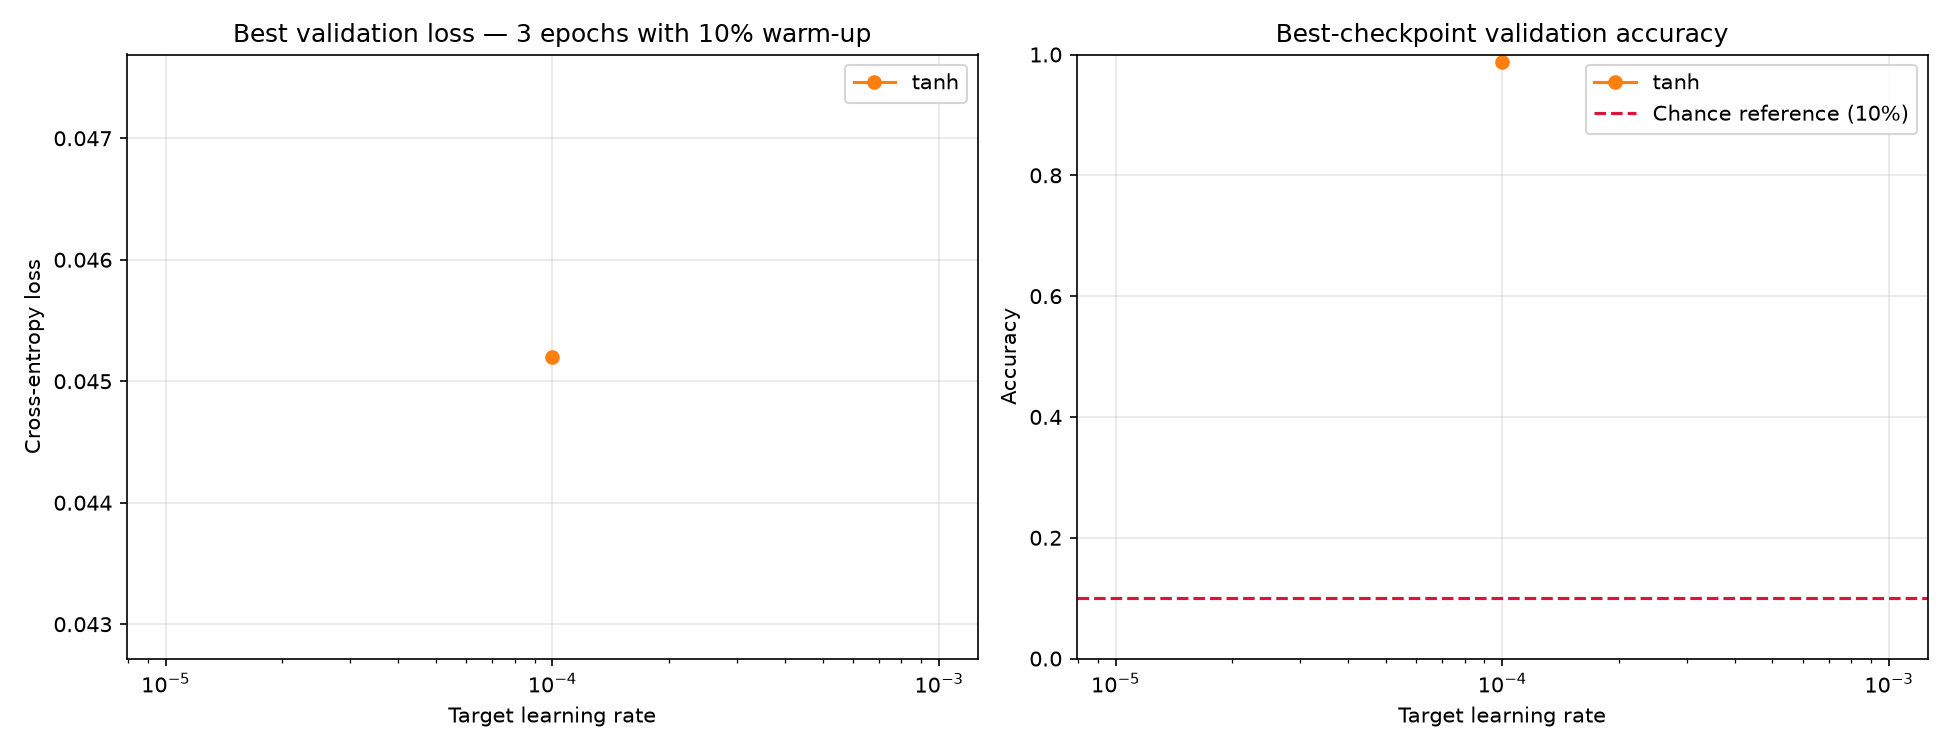

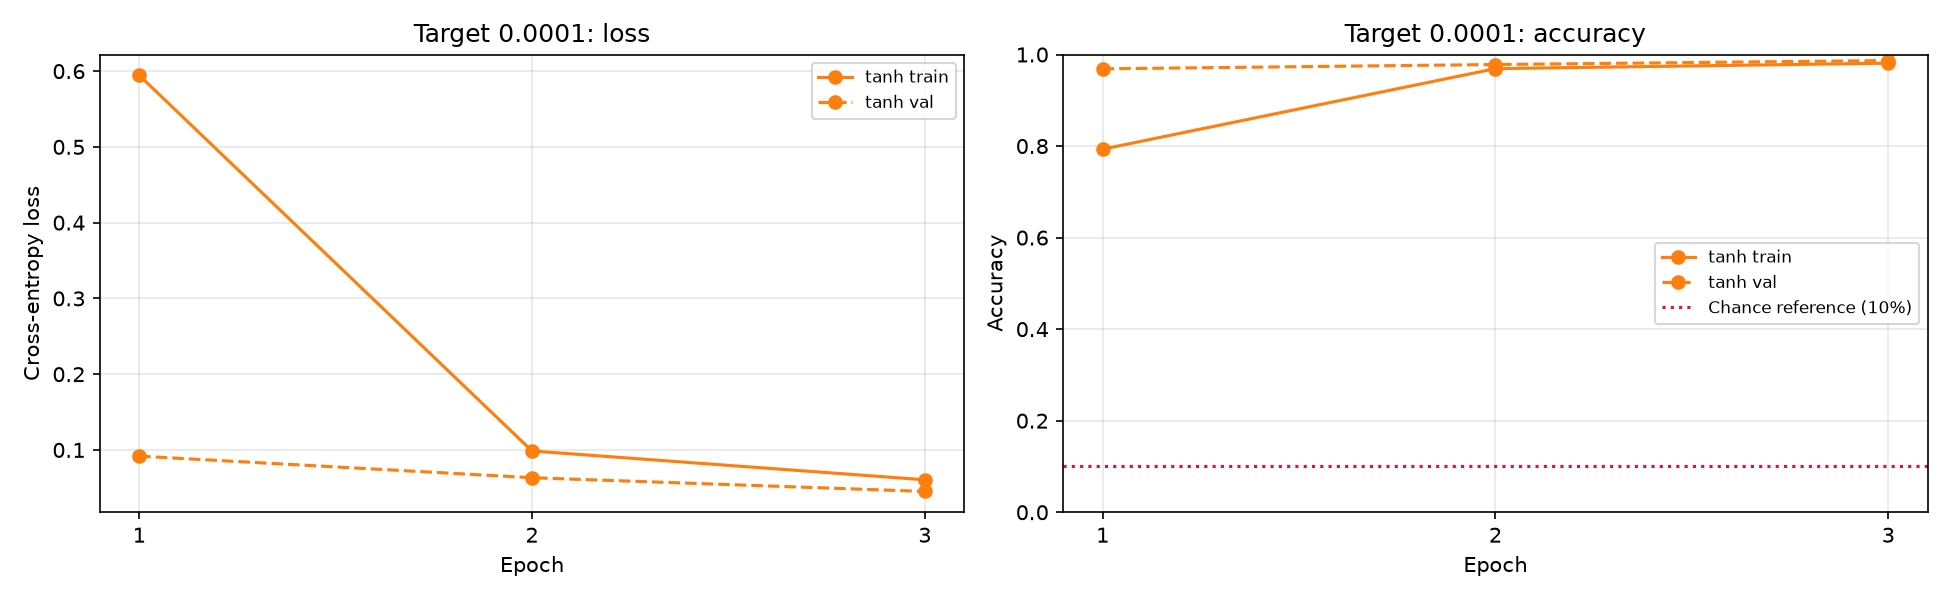

### TANH · target 0.0001 · 20261030_142314_039b2794

Selected minimum-loss checkpoint: epoch 3, accuracy 98.68%, loss 0.045203
Peak observed accuracy: 98.68%, epoch 3; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.594488,0.091806,0.793157,0.968690,5.770340e-08,0.0001,5775
1,2,0.098602,0.063322,0.969104,0.978095,1.000000e-04,0.0001,11550
2,3,0.060596,0.045203,0.981028,0.986786,1.000000e-04,0.0001,17325


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
9,838,826,12,0.972909,0.985680,0.979253,0.995833
8,813,790,23,0.987500,0.971710,0.979541,0.996071
5,759,747,12,0.982895,0.984190,0.983542,0.997024
7,880,875,5,0.973304,0.994318,0.983699,0.996548
2,835,822,13,0.987981,0.984431,0.986203,0.997262
3,870,858,12,0.987342,0.986207,0.986774,0.997262
4,814,803,11,0.988916,0.986486,0.987700,0.997619
6,827,819,8,0.992727,0.990326,0.991525,0.998333
0,827,819,8,0.996350,0.990326,0.993329,0.998690


... (3 outputs left out)

,Logit,Probability
Digit,,
0,-2.063814,0.000002
1,11.029030,0.999887
2,-1.050482,0.000006
3,-0.862198,0.000007
4,-0.748072,0.000008
5,0.304275,0.000022
6,-1.658084,0.000003
7,0.803760,0.000036
8,0.498599,0.000027


### Bespoke Conventional CNN — learning-rate testing

Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 4 / 4


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_143705_1077c38e,relu,0.00050,3,0.041263,0.990357,0.990257,151.544853,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...
1,20261030_143937_9823b3b6,relu,0.00075,3,0.033286,0.991429,0.991339,149.776818,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...
2,20261030_144207_b32afc08,relu,0.00125,3,0.052139,0.987262,0.987171,149.250273,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...
3,20261030_144437_09ca63e5,relu,0.00150,2,0.054145,0.985595,0.985485,149.186254,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


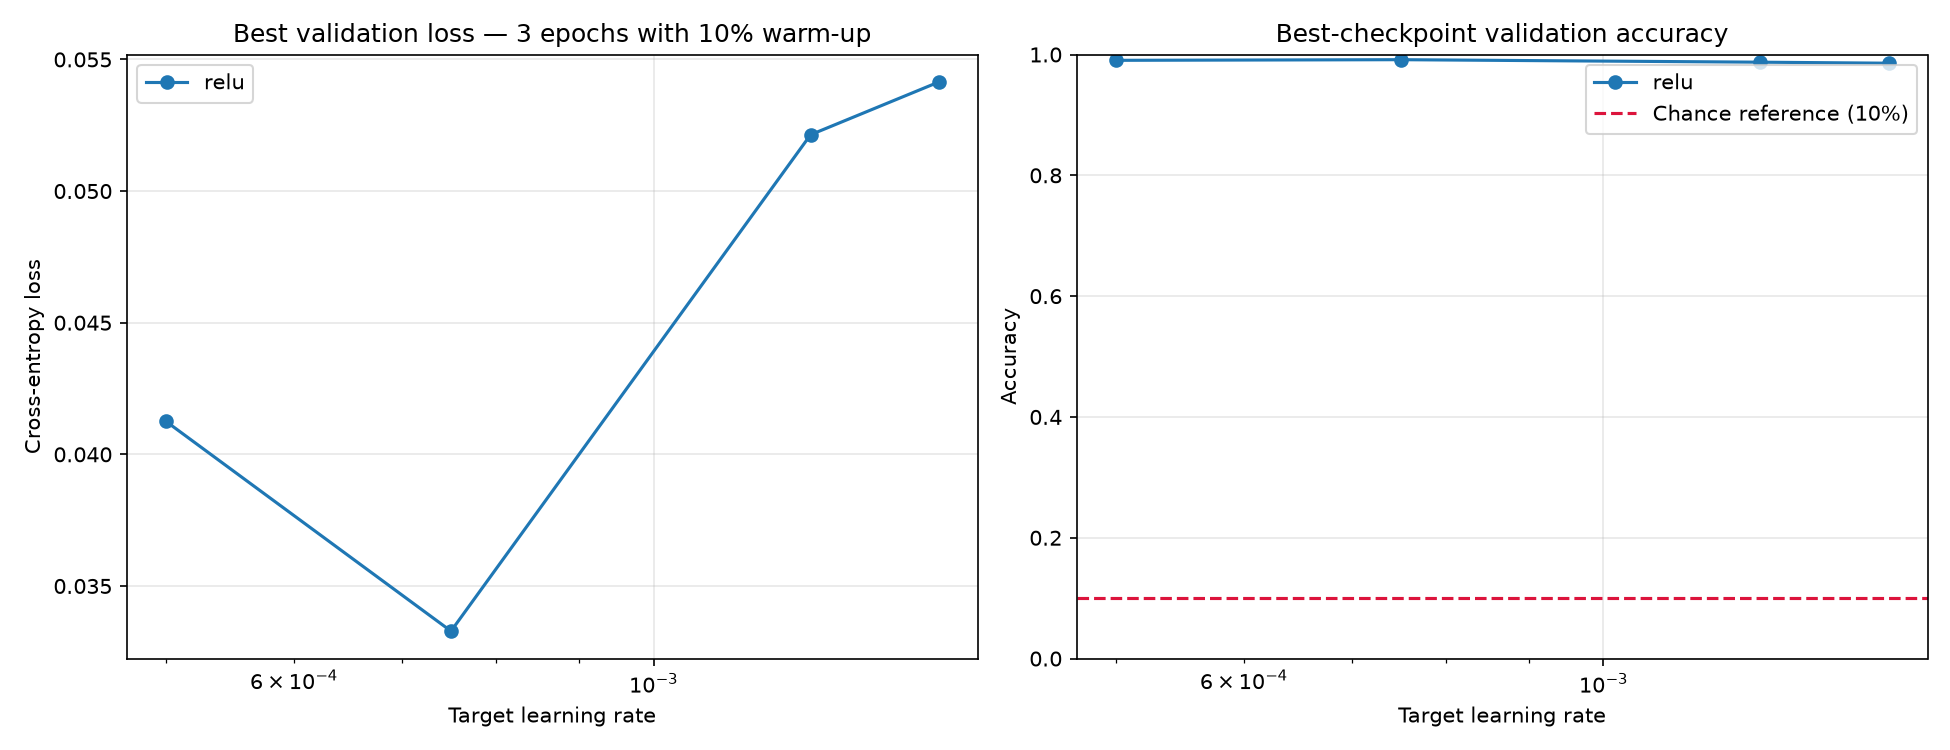

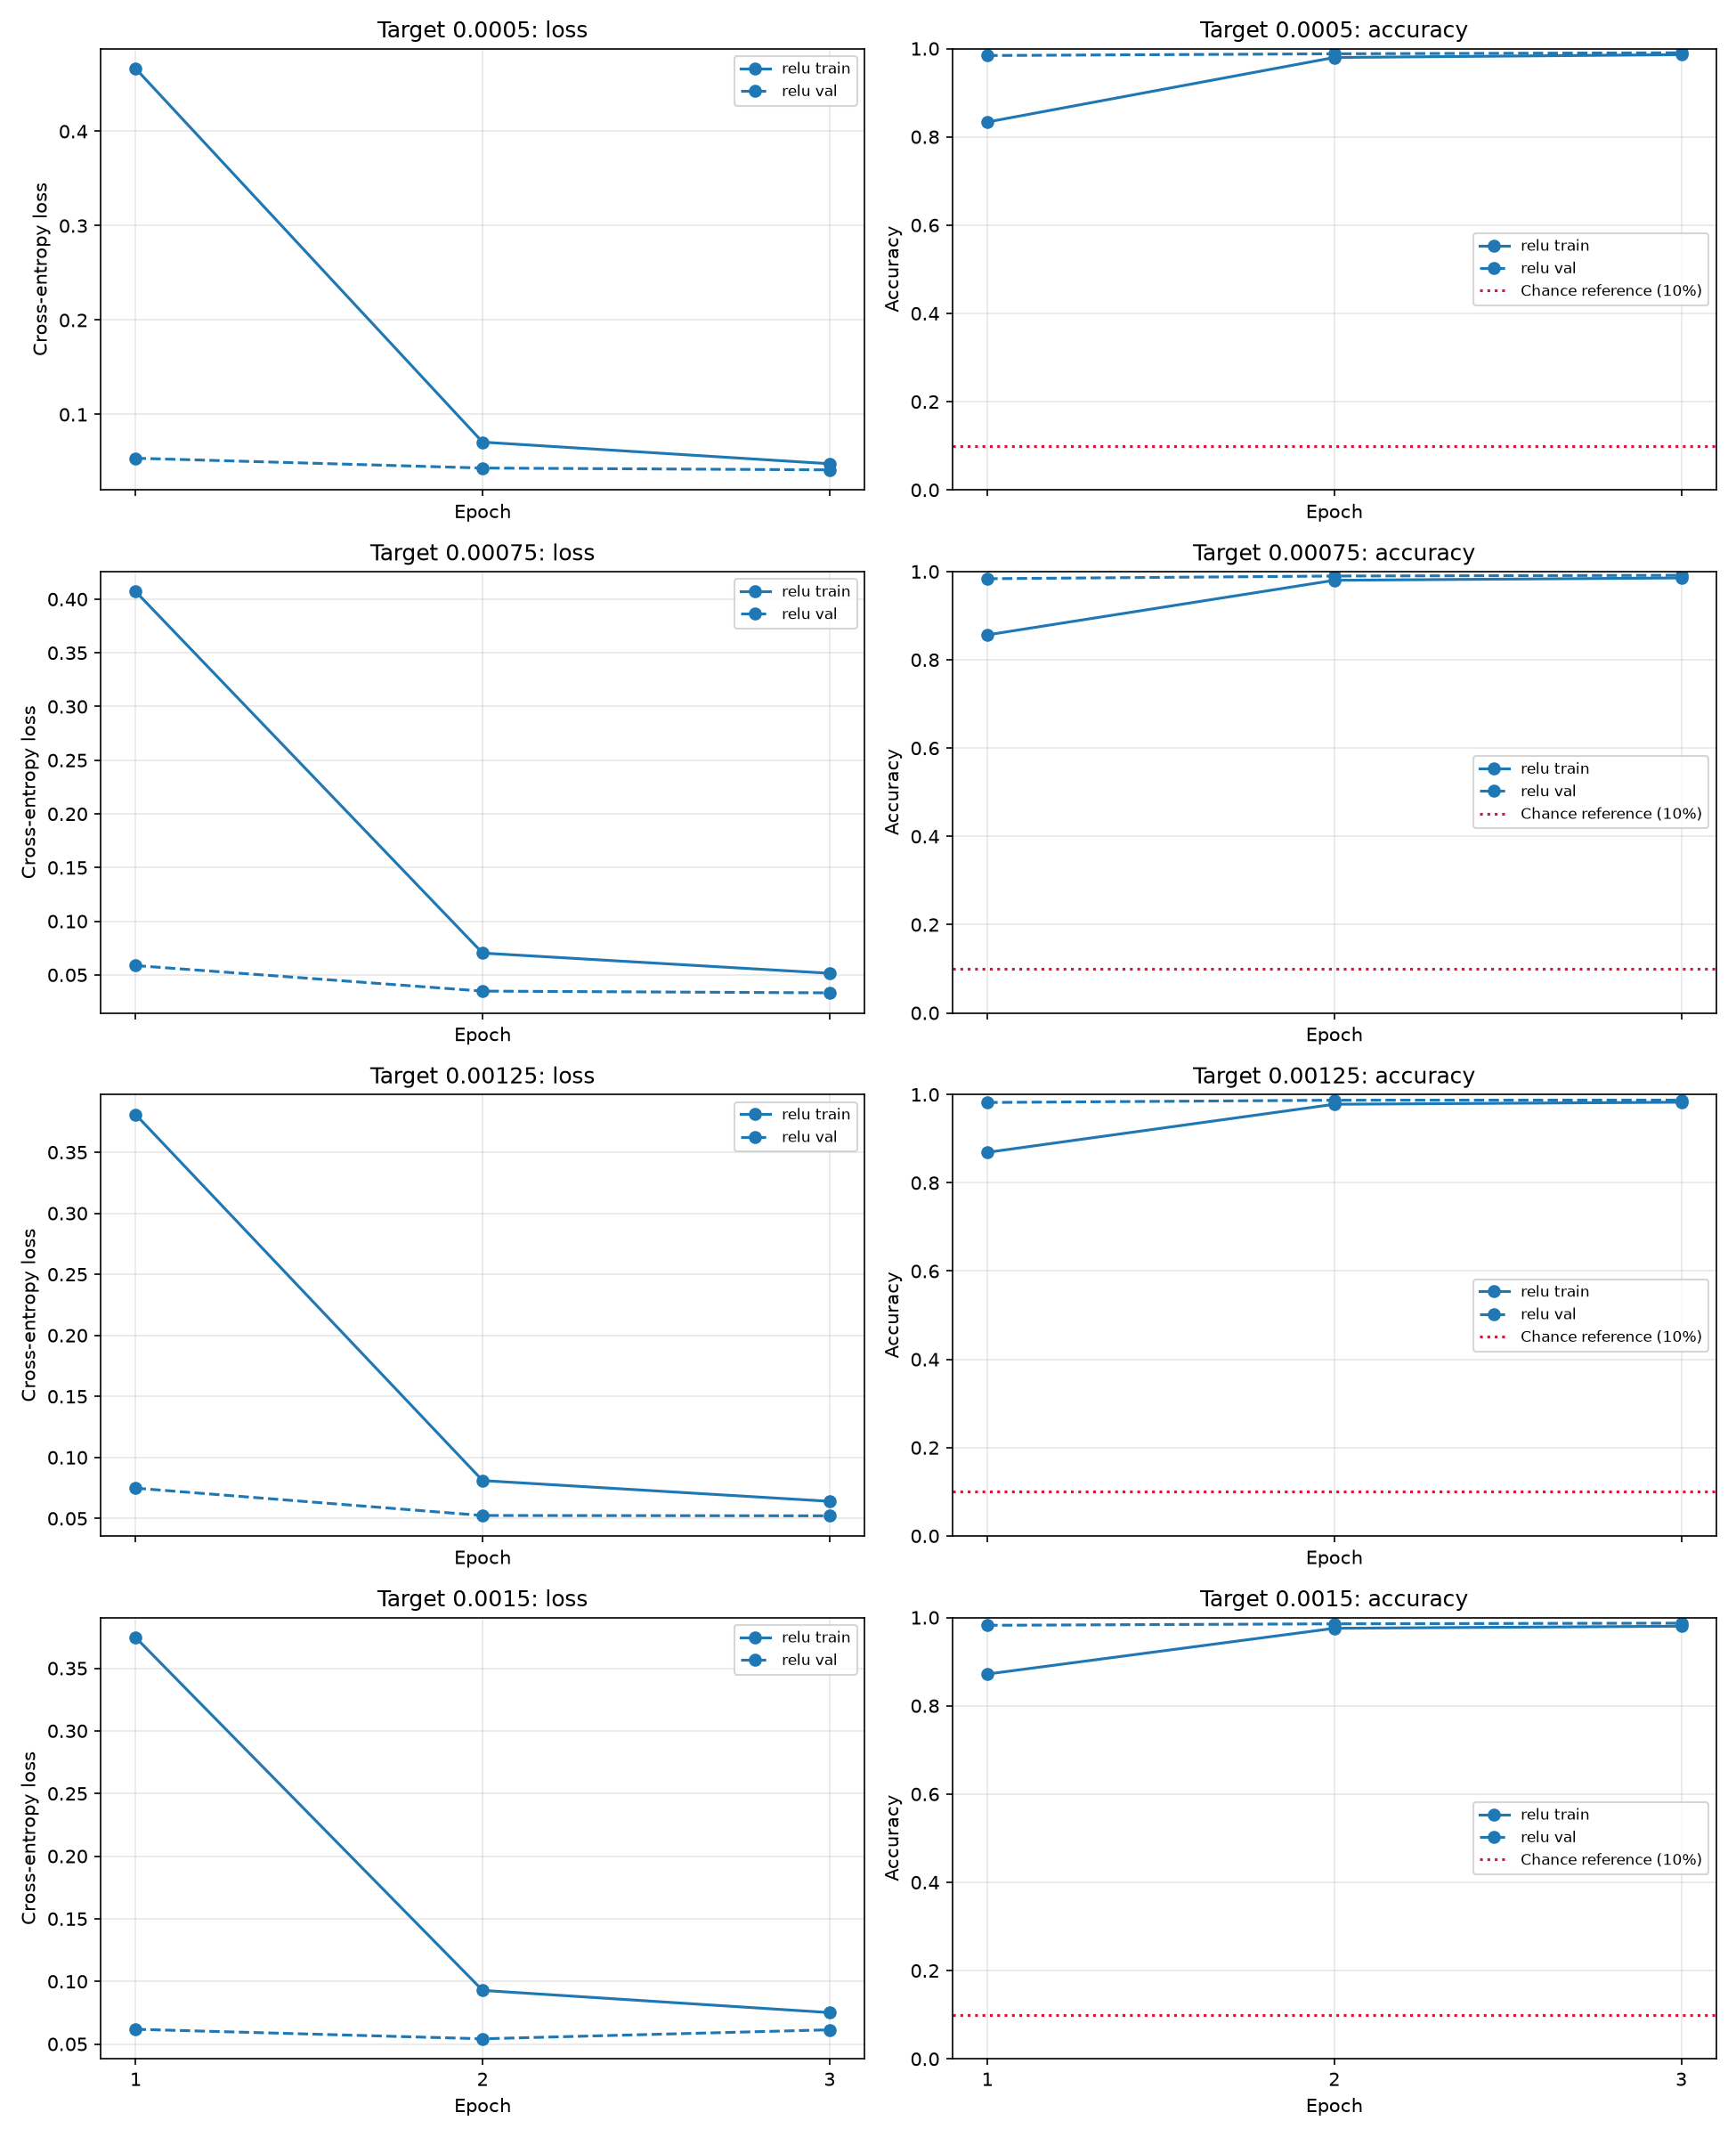

### RELU · target 0.0005 · 20261030_143705_1077c38e

Selected minimum-loss checkpoint: epoch 3, accuracy 99.04%, loss 0.041263
Peak observed accuracy: 99.04%, epoch 3; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.466434,0.053596,0.833506,0.984167,2.885170e-07,0.0005,5775
1,2,0.070656,0.043190,0.979727,0.988095,5.000000e-04,0.0005,11550
2,3,0.047749,0.041263,0.986088,0.990357,5.000000e-04,0.0005,17325


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
5,759,748,11,0.984211,0.985507,0.984858,0.997262
9,838,820,18,0.991536,0.978520,0.984985,0.997024
7,880,869,11,0.983032,0.987500,0.985261,0.996905
8,813,806,7,0.984127,0.991390,0.987745,0.997619
4,814,808,6,0.986569,0.992629,0.989590,0.997976
0,827,820,7,0.993939,0.991536,0.992736,0.998571
2,835,831,4,0.990465,0.995210,0.992832,0.998571
6,827,822,5,0.995157,0.993954,0.994555,0.998929
3,870,863,7,0.997688,0.991954,0.994813,0.998929


... (33 outputs left out)

,Logit,Probability
Digit,,
0,-16.840048,1.048184e-13
1,13.046499,9.999998e-01
2,-6.784668,2.440245e-09
3,-14.031604,1.738319e-12
4,-3.475439,6.677490e-08
5,-9.948977,1.030841e-10
6,-6.641626,2.815500e-09
7,-3.002995,1.071009e-07
8,-8.062920,6.796663e-10


### Bespoke Conventional CNN — learning-rate testing

Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_143050_495b4a16,relu,0.001,2,0.046218,0.987619,0.987547,149.740284,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


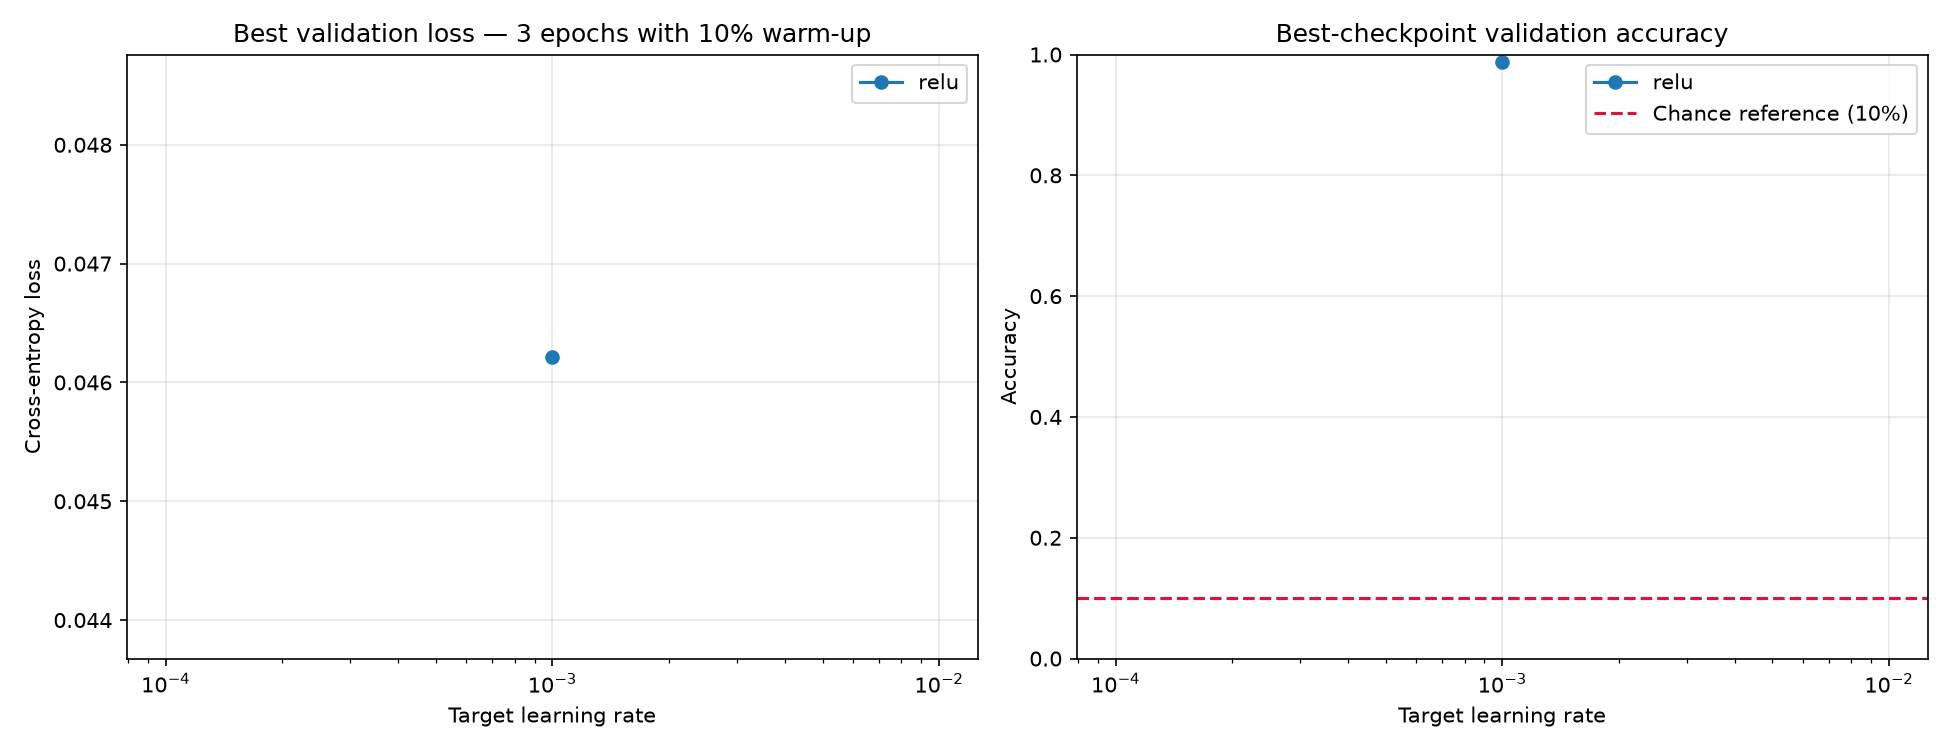

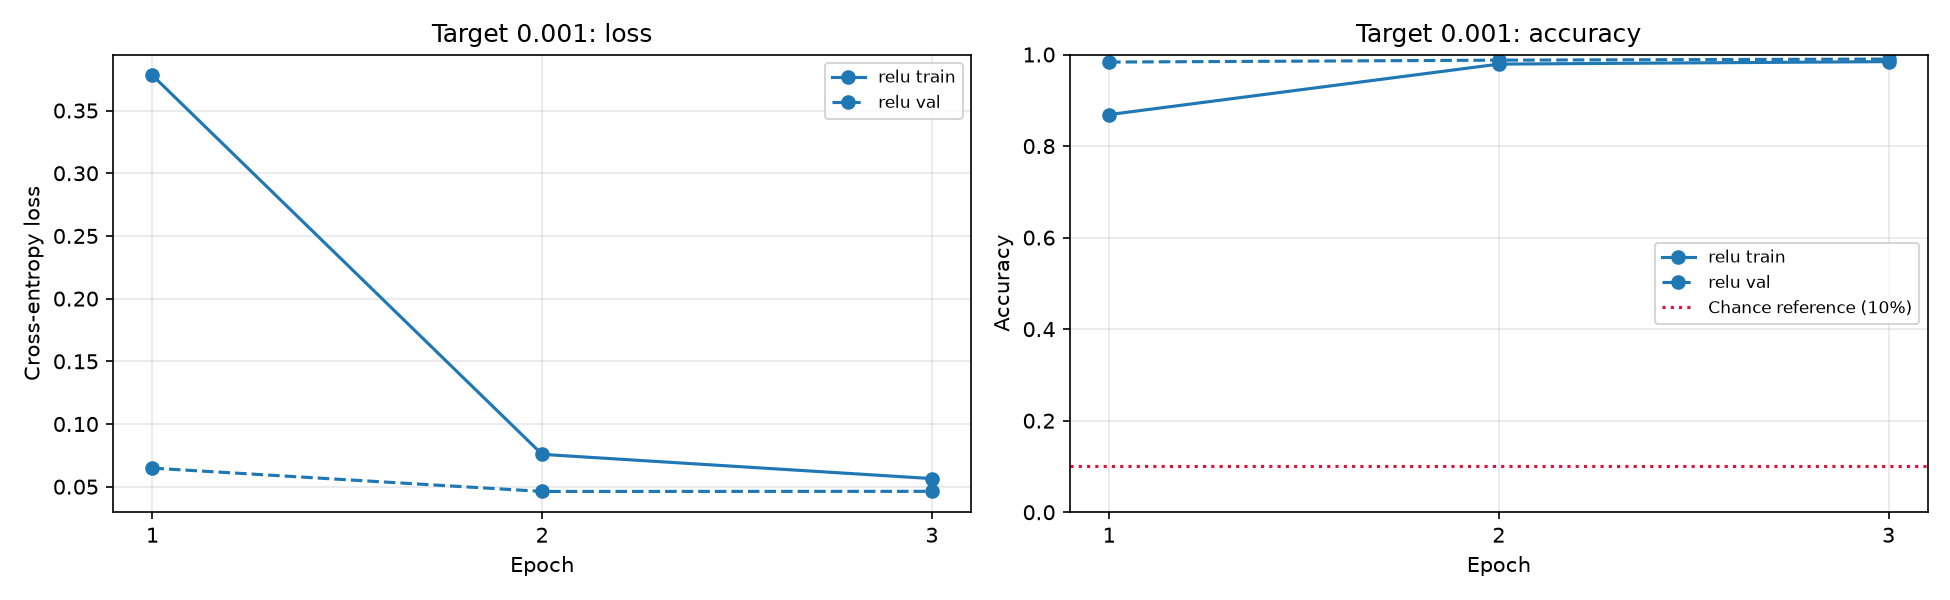

### RELU · target 0.001 · 20261030_143050_495b4a16

Selected minimum-loss checkpoint: epoch 2, accuracy 98.76%, loss 0.046218
Peak observed accuracy: 99.00%, epoch 3; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.378116,0.064813,0.868701,0.983452,5.770340e-07,0.001,5775
1,2,0.075795,0.046218,0.979023,0.987619,1.000000e-03,0.001,11550
2,3,0.056464,0.046300,0.984413,0.990000,1.000000e-03,0.001,17325


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
5,759,748,11,0.979058,0.985507,0.982272,0.996786
9,838,824,14,0.982122,0.983294,0.982707,0.996548
4,814,804,10,0.979294,0.987715,0.983486,0.996786
7,880,871,9,0.977553,0.989773,0.983625,0.996548
3,870,855,15,0.994186,0.982759,0.988439,0.997619
8,813,799,14,0.996259,0.982780,0.989474,0.997976
6,827,821,6,0.989157,0.992745,0.990947,0.998214
0,827,826,1,0.983333,0.998791,0.991002,0.998214
2,835,821,14,1.000000,0.983234,0.991546,0.998333


... (3 outputs left out)

,Logit,Probability
Digit,,
0,-14.521169,8.610667e-12
1,10.956845,9.999946e-01
2,-9.066240,2.014103e-09
3,-10.585922,4.406492e-10
4,-4.671411,1.632046e-07
5,-8.568884,3.311927e-09
6,-6.391750,2.921452e-08
7,-4.353351,2.243180e-07
8,-1.322592,4.646286e-06


### Bespoke Conventional CNN — learning-rate testing

Regularization: {'l2_strength': 0.0, 'decoupled_weight_decay': 0.0, 'l2_convention': 'lambda/2 * sum(weight_squared)', 'parameter_policy': 'named weight tensors only; biases excluded', 'validation_loss': 'unpenalized_cross_entropy'}
Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_165357_fab04b1d,relu,0.00075,3,0.039912,0.989881,0.989799,658.791918,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


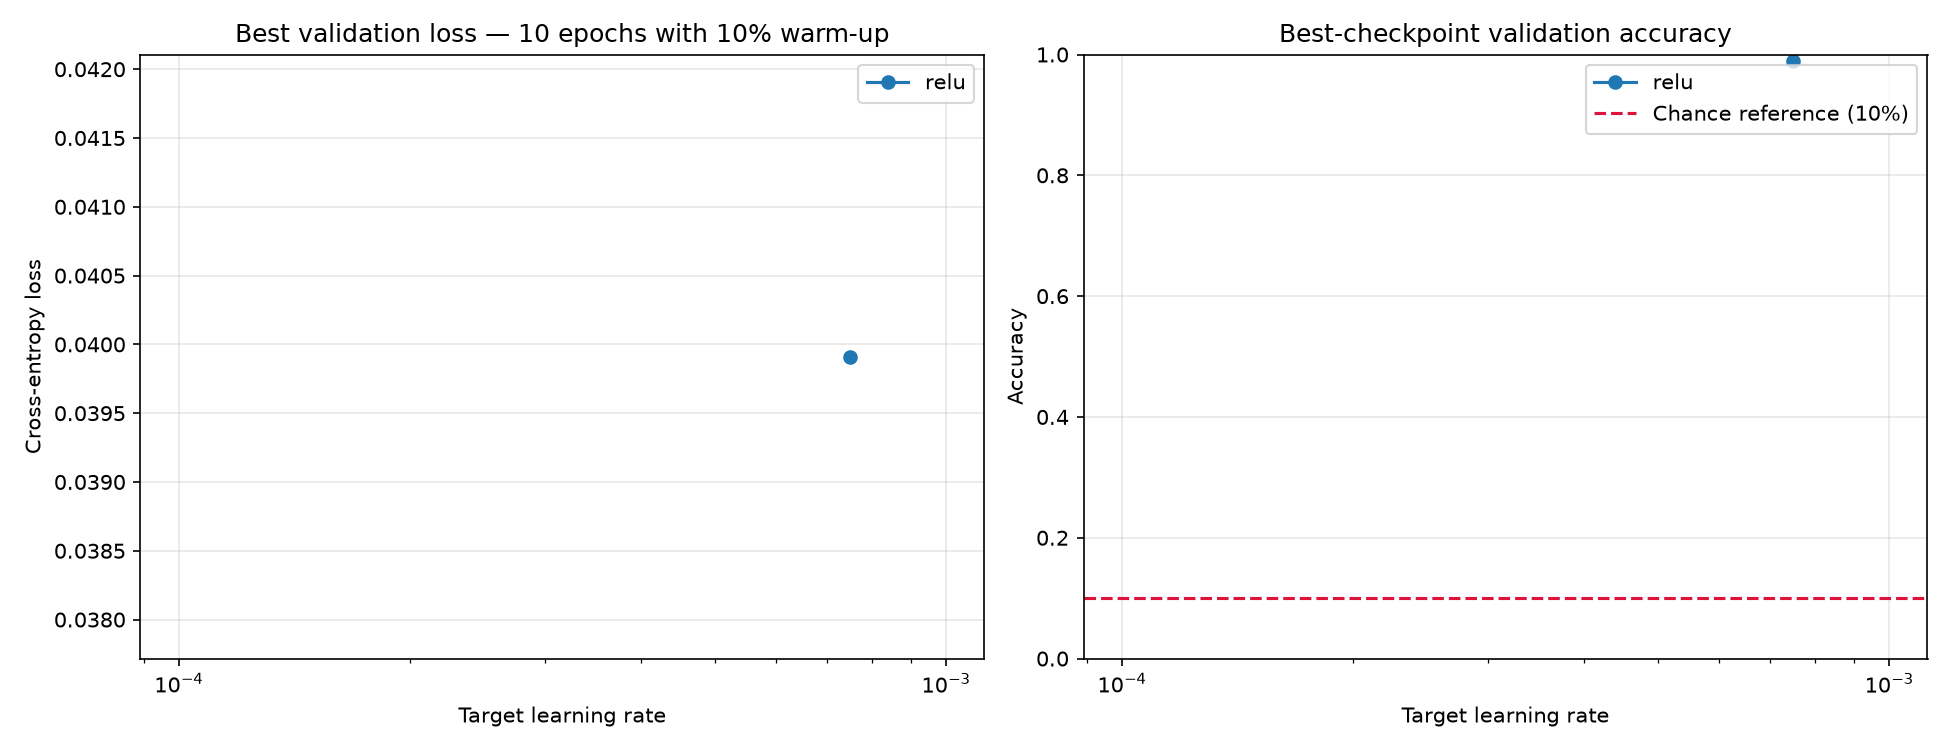

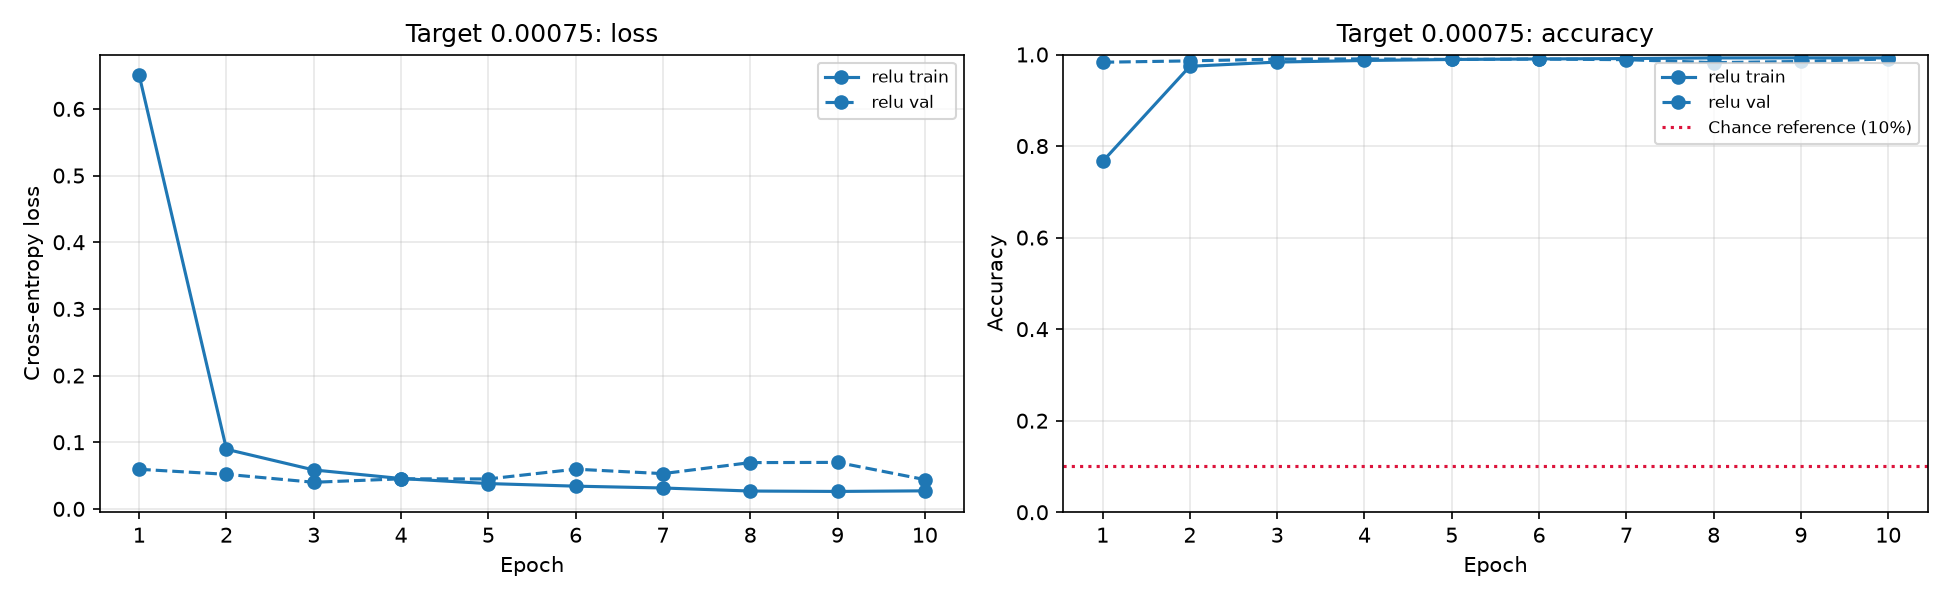

### RELU · target 0.00075 · 20261030_165357_fab04b1d

Selected minimum-loss checkpoint: epoch 3, accuracy 98.99%, loss 0.039912
Peak observed accuracy: 99.04%, epoch 4; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.650395,0.059417,0.766326,0.983095,1.298701e-07,0.00075,5775
1,2,0.089395,0.051858,0.974280,0.986071,7.500000e-04,0.00075,11550
2,3,0.058404,0.039912,0.983447,0.989881,7.500000e-04,0.00075,17325
3,4,0.045539,0.045115,0.986937,0.990357,7.500000e-04,0.00075,23100
4,5,0.037977,0.044929,0.989145,0.989286,7.500000e-04,0.00075,28875
5,6,0.034095,0.059560,0.990284,0.990000,7.500000e-04,0.00075,34650
6,7,0.031352,0.052888,0.991153,0.988690,7.500000e-04,0.00075,40425
7,8,0.026778,0.069440,0.992511,0.982262,7.500000e-04,0.00075,46200
8,9,0.026175,0.069751,0.992643,0.984762,7.500000e-04,0.00075,51975
9,10,0.027075,0.043935,0.992562,0.990357,7.500000e-04,0.00075,57750


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
5,759,747,12,0.986790,0.984190,0.985488,0.997381
7,880,873,7,0.979798,0.992045,0.985884,0.997024
4,814,805,9,0.985312,0.988943,0.987124,0.997500
8,813,803,10,0.987700,0.987700,0.987700,0.997619
3,870,859,11,0.990773,0.987356,0.989062,0.997738
2,835,825,10,0.991587,0.988024,0.989802,0.997976
9,838,829,9,0.991627,0.989260,0.990442,0.998095
6,827,821,6,0.991546,0.992745,0.992145,0.998452
0,827,822,5,0.996364,0.993954,0.995157,0.999048


... (3 outputs left out)

,Logit,Probability
Digit,,
0,-24.815668,2.392792e-17
1,13.455810,9.999909e-01
2,-6.698845,1.765796e-09
3,-7.989081,4.859575e-10
4,-4.017760,2.578227e-08
5,-11.547001,1.384883e-11
6,-8.442483,3.088079e-10
7,1.850606,9.118432e-06
8,-5.679333,4.894507e-09


### Bespoke Conventional CNN — learning-rate testing

Regularization: {'l2_strength': 1e-05, 'decoupled_weight_decay': 0.0, 'l2_convention': 'lambda/2 * sum(weight_squared)', 'parameter_policy': 'named weight tensors only; biases excluded', 'validation_loss': 'unpenalized_cross_entropy'}
Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_170459_8581fe19,relu,0.00075,5,0.036779,0.989762,0.989751,563.827662,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


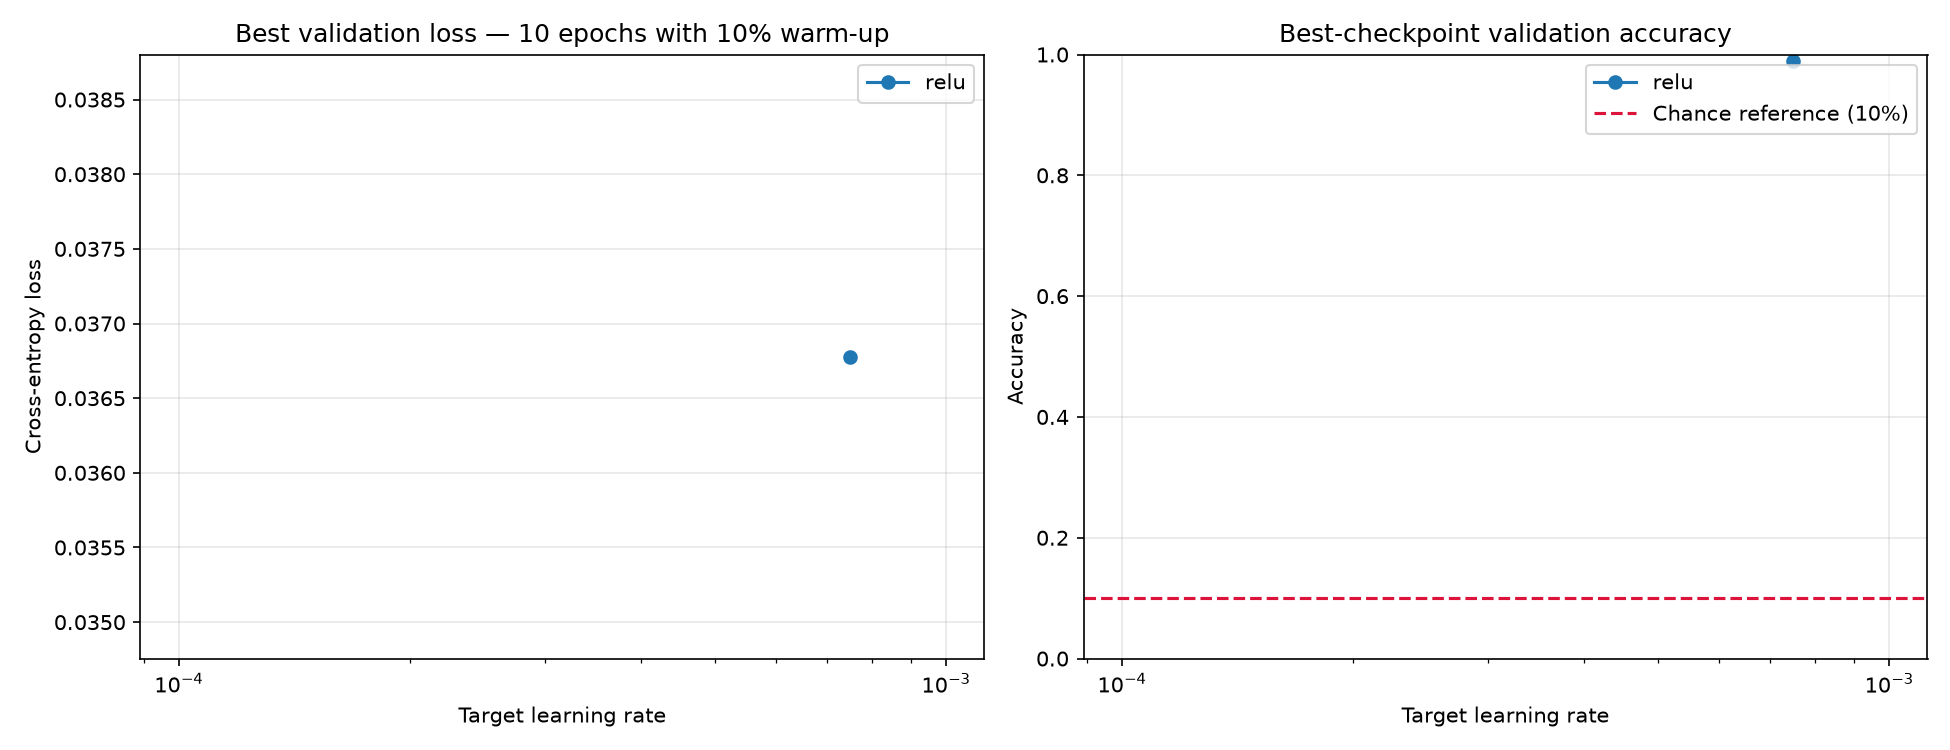

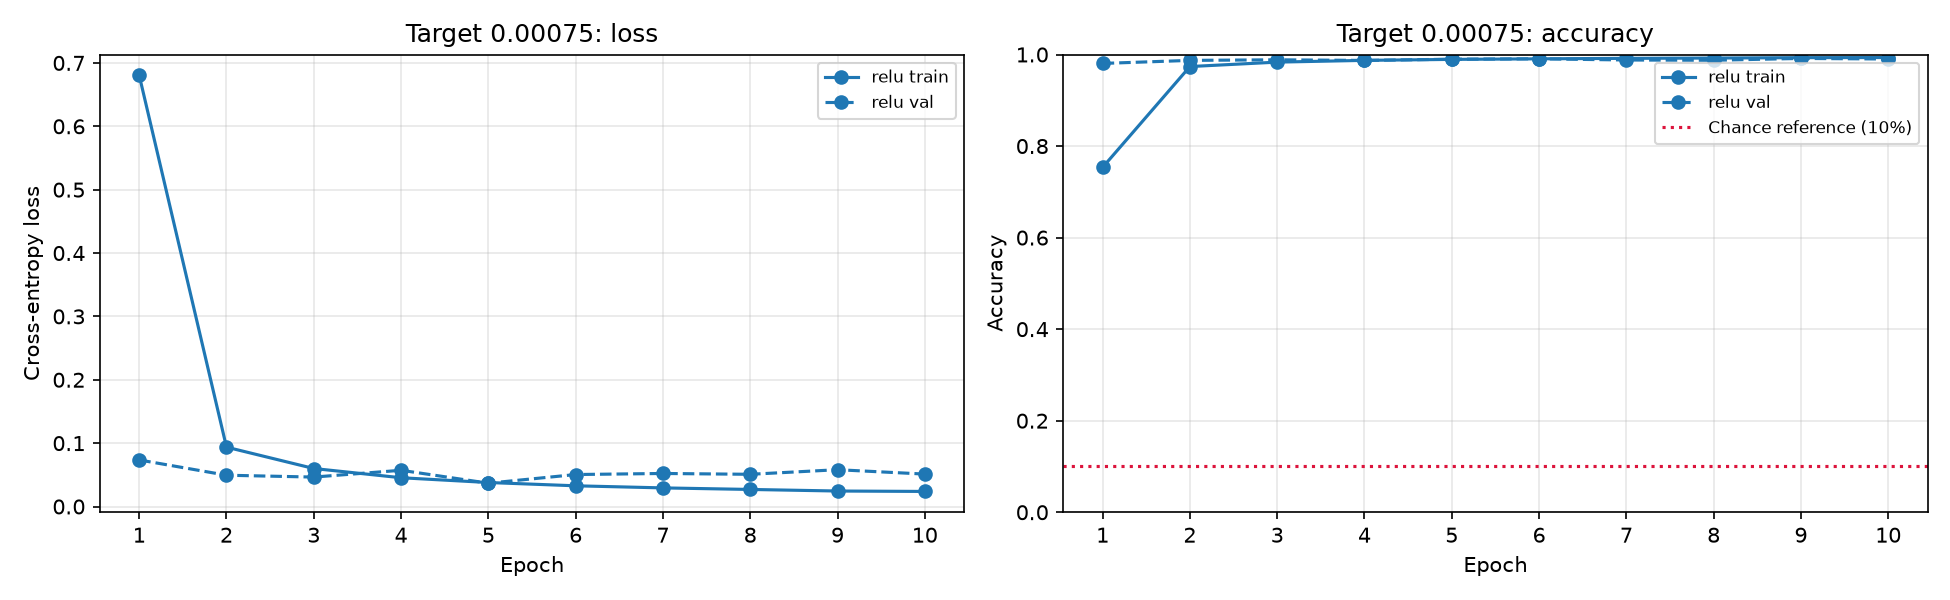

### RELU · target 0.00075 · 20261030_170459_8581fe19

Selected minimum-loss checkpoint: epoch 5, accuracy 98.98%, loss 0.036779
Peak observed accuracy: 99.14%, epoch 9; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_l2_penalty,train_objective,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.680476,0.073469,0.753436,0.980476,0.002031,0.682507,1.298701e-07,0.00075,5775
1,2,0.093685,0.049376,0.973677,0.987143,0.005286,0.098971,7.500000e-04,0.00075,11550
2,3,0.059963,0.046444,0.983341,0.988452,0.007935,0.067898,7.500000e-04,0.00075,17325
3,4,0.045401,0.057178,0.987175,0.987024,0.010175,0.055576,7.500000e-04,0.00075,23100
4,5,0.037860,0.036779,0.989326,0.989762,0.012095,0.049955,7.500000e-04,0.00075,28875
5,6,0.032676,0.050456,0.990574,0.990595,0.013742,0.046418,7.500000e-04,0.00075,34650
6,7,0.029366,0.052138,0.991591,0.987976,0.015224,0.044590,7.500000e-04,0.00075,40425
7,8,0.026918,0.050822,0.992289,0.987381,0.016517,0.043435,7.500000e-04,0.00075,46200
8,9,0.024436,0.058072,0.993128,0.991429,0.017625,0.042061,7.500000e-04,0.00075,51975
9,10,0.023779,0.051169,0.993331,0.990119,0.018606,0.042385,7.500000e-04,0.00075,57750


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
7,880,871,9,0.967778,0.989773,0.978652,0.995476
9,838,825,13,0.988024,0.984487,0.986252,0.997262
4,814,798,16,0.992537,0.980344,0.986403,0.997381
5,759,747,12,0.996000,0.984190,0.990060,0.998214
8,813,803,10,0.992583,0.987700,0.990136,0.998095
2,835,825,10,0.992780,0.988024,0.990396,0.998095
6,827,823,4,0.987995,0.995163,0.991566,0.998333
3,870,865,5,0.990836,0.994253,0.992542,0.998452
1,937,934,3,0.994675,0.996798,0.995736,0.999048


... (3 outputs left out)

,Logit,Probability
Digit,,
0,-15.322902,3.434550e-13
1,13.376819,1.000000e+00
2,-7.935215,5.550113e-10
3,-16.683760,8.807590e-14
4,-10.805334,3.146480e-11
5,-10.348996,4.966032e-11
6,-11.022729,2.531694e-11
7,-3.337042,5.511403e-08
8,-4.680960,1.437497e-08


### Bespoke Conventional CNN — learning-rate testing

Regularization: {'l2_strength': 0.0, 'decoupled_weight_decay': 0.001, 'l2_convention': 'lambda/2 * sum(weight_squared)', 'parameter_policy': 'named weight tensors only; biases excluded', 'validation_loss': 'unpenalized_cross_entropy'}
Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_171425_831564a1,relu,0.00075,3,0.043292,0.990357,0.990313,512.745275,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


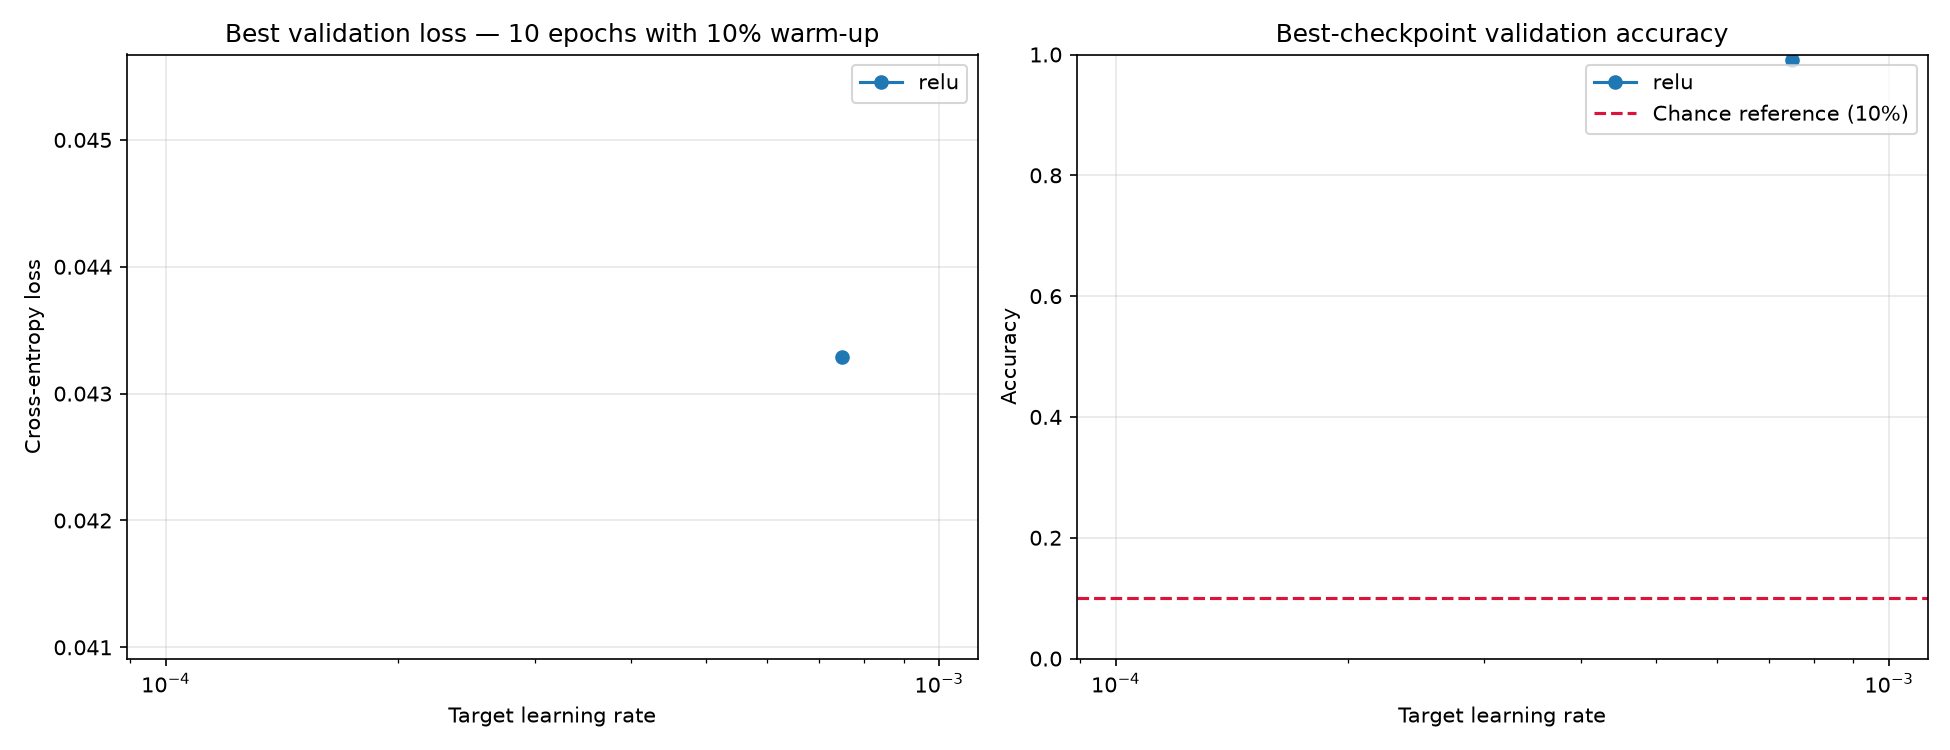

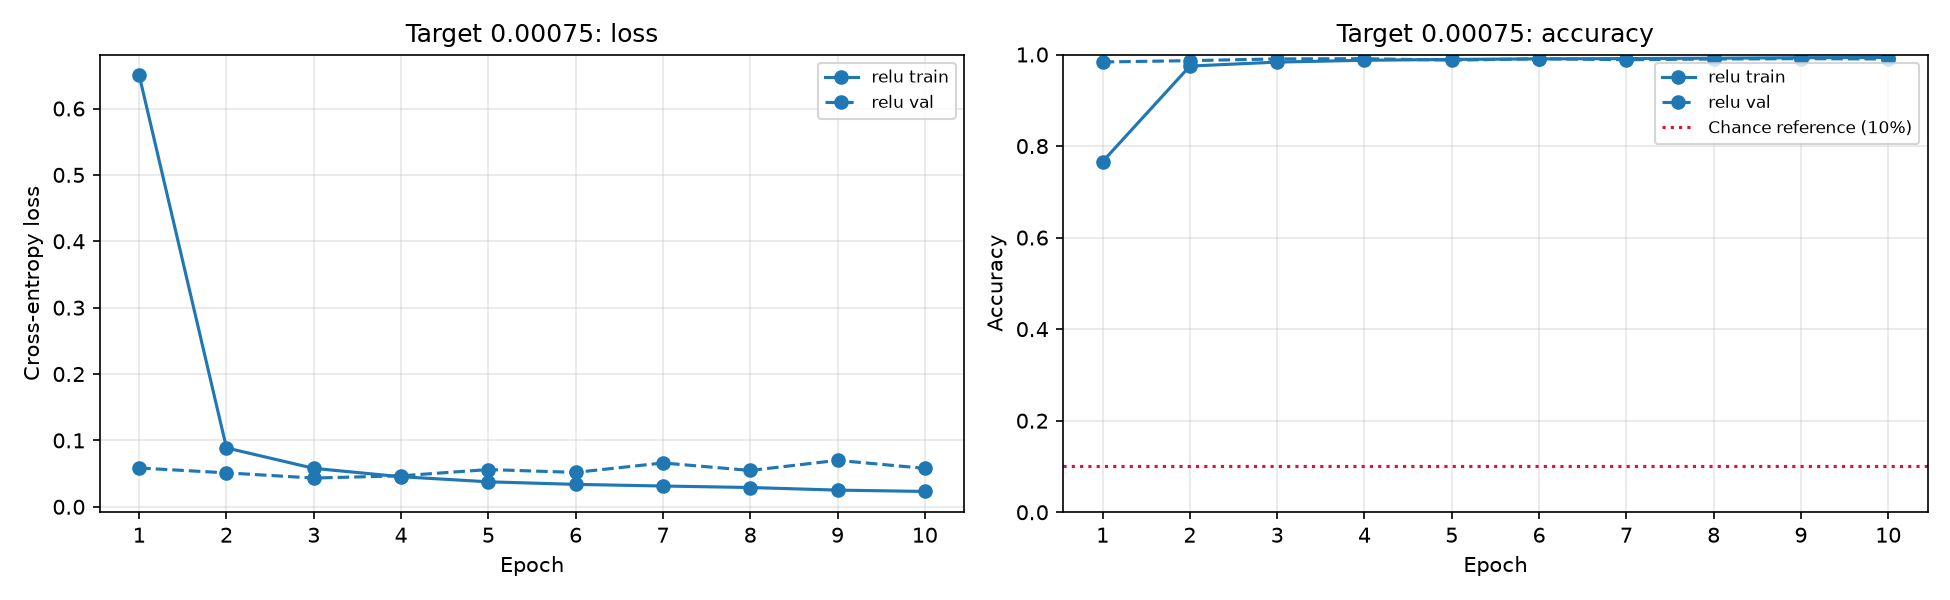

### RELU · target 0.00075 · 20261030_171425_831564a1

Selected minimum-loss checkpoint: epoch 3, accuracy 99.04%, loss 0.043292
Peak observed accuracy: 99.08%, epoch 4; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_l2_penalty,train_objective,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.650045,0.058434,0.766055,0.983690,0.0,0.650045,1.298701e-07,0.00075,5775
1,2,0.088727,0.051132,0.974689,0.986548,0.0,0.088727,7.500000e-04,0.00075,11550
2,3,0.057897,0.043292,0.983385,0.990357,0.0,0.057897,7.500000e-04,0.00075,17325
3,4,0.045302,0.046667,0.987386,0.990833,0.0,0.045302,7.500000e-04,0.00075,23100
4,5,0.037627,0.056086,0.989294,0.987619,0.0,0.037627,7.500000e-04,0.00075,28875
5,6,0.033766,0.051806,0.990430,0.990714,0.0,0.033766,7.500000e-04,0.00075,34650
6,7,0.031295,0.066003,0.991058,0.988571,0.0,0.031295,7.500000e-04,0.00075,40425
7,8,0.029038,0.054731,0.991929,0.990119,0.0,0.029038,7.500000e-04,0.00075,46200
8,9,0.025107,0.069954,0.993052,0.990833,0.0,0.025107,7.500000e-04,0.00075,51975
9,10,0.023123,0.057893,0.993377,0.990238,0.0,0.023123,7.500000e-04,0.00075,57750


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
7,880,873,7,0.977604,0.992045,0.984772,0.996786
9,838,820,18,0.993939,0.978520,0.986170,0.997262
8,813,806,7,0.982927,0.991390,0.987140,0.997500
3,870,860,10,0.990783,0.988506,0.989643,0.997857
2,835,820,15,0.997567,0.982036,0.989740,0.997976
5,759,755,4,0.985640,0.994730,0.990164,0.998214
4,814,805,9,0.993827,0.988943,0.991379,0.998333
0,827,822,5,0.991556,0.993954,0.992754,0.998571
6,827,825,2,0.991587,0.997582,0.994575,0.998929


... (3 outputs left out)

,Logit,Probability
Digit,,
0,-20.750319,3.078052e-14
1,10.361571,9.999945e-01
2,-8.846082,4.552185e-09
3,-9.946044,1.515348e-09
4,-2.579500,2.397519e-06
5,-9.184285,3.245936e-09
6,-6.384109,5.338771e-08
7,-2.381929,2.921232e-06
8,-5.808550,9.492985e-08


### Bespoke Conventional CNN — learning-rate testing

Regularization: {'l2_strength': 1e-05, 'decoupled_weight_decay': 0.001, 'l2_convention': 'lambda/2 * sum(weight_squared)', 'parameter_policy': 'named weight tensors only; biases excluded', 'validation_loss': 'unpenalized_cross_entropy'}
Training augmentation: {'type': 'fixed_rotation_views', 'angles_degrees': [0.0, -5.0, 5.0, -10.0, 10.0, -22.0, 22.0, -45.0, 45.0, -90.0, 90.0], 'views_per_original': 11, 'generation': 'lazy_original_major', 'interpolation': 'bilinear', 'fill': 0.0, 'align_corners': False, 'rotation_center': 'image_center', 'seed': 42, 'training_only': True, 'num_workers': 0, 'split_before_augmentation': True}
Status: completed | completed: 1 / 1


,run_id,activation,target_learning_rate,best_epoch,val_loss,val_accuracy,macro_f1,elapsed_seconds,checkpoint_path,validation_outputs
0,20261030_172301_1d257a0d,relu,0.00075,3,0.037559,0.990357,0.990311,549.778534,/Users/KurtMeehanPro/Documents/code/git/digit-...,/Users/KurtMeehanPro/Documents/code/git/digit-...


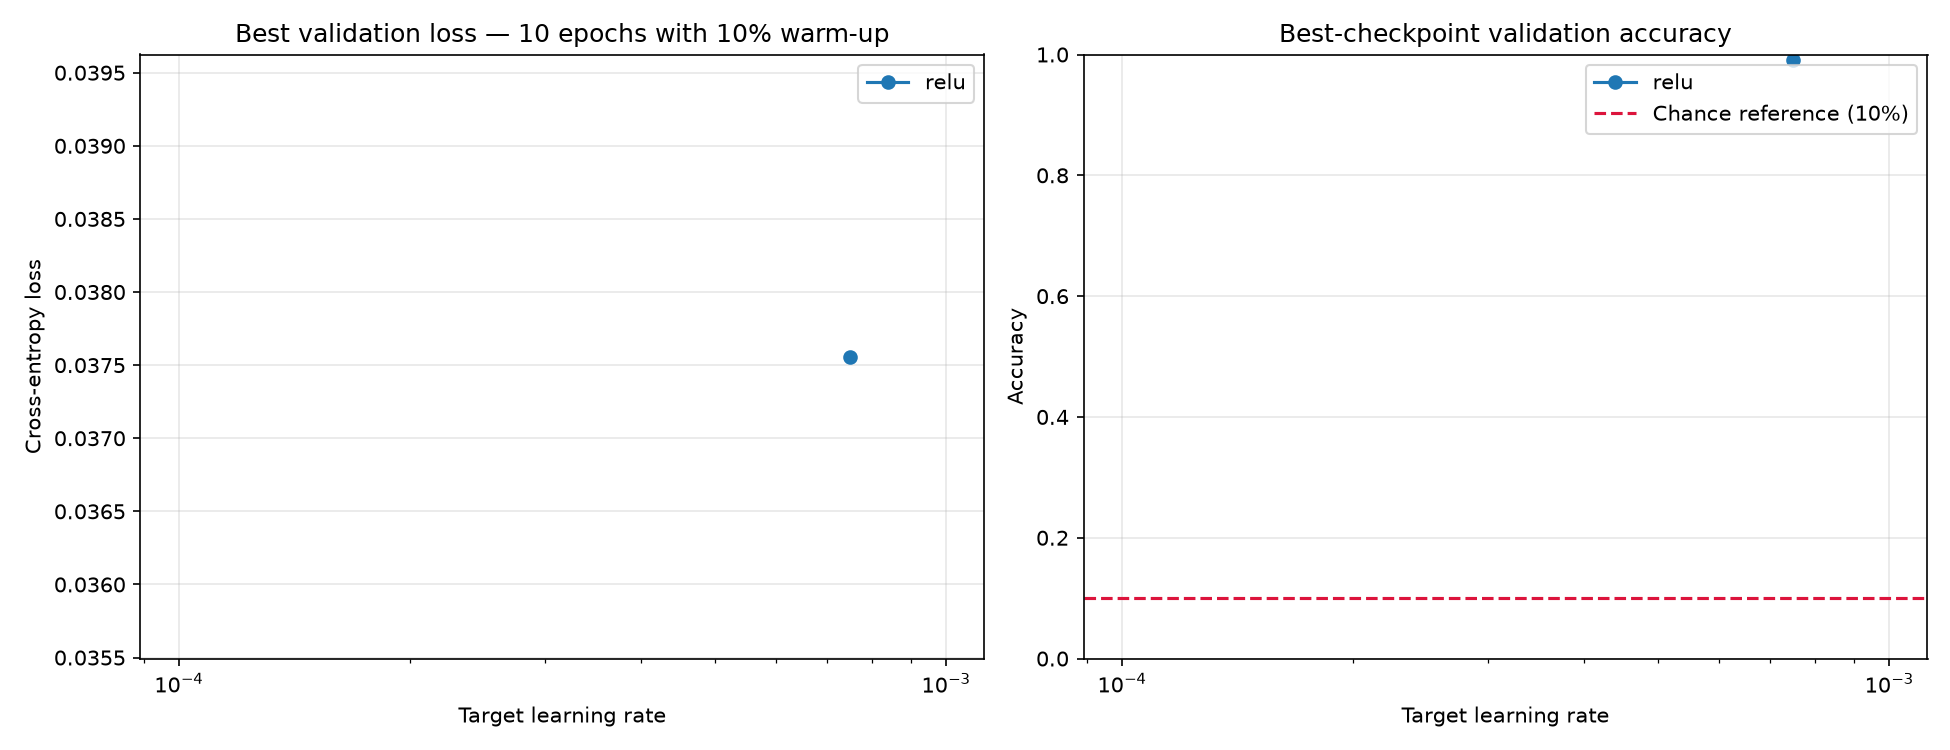

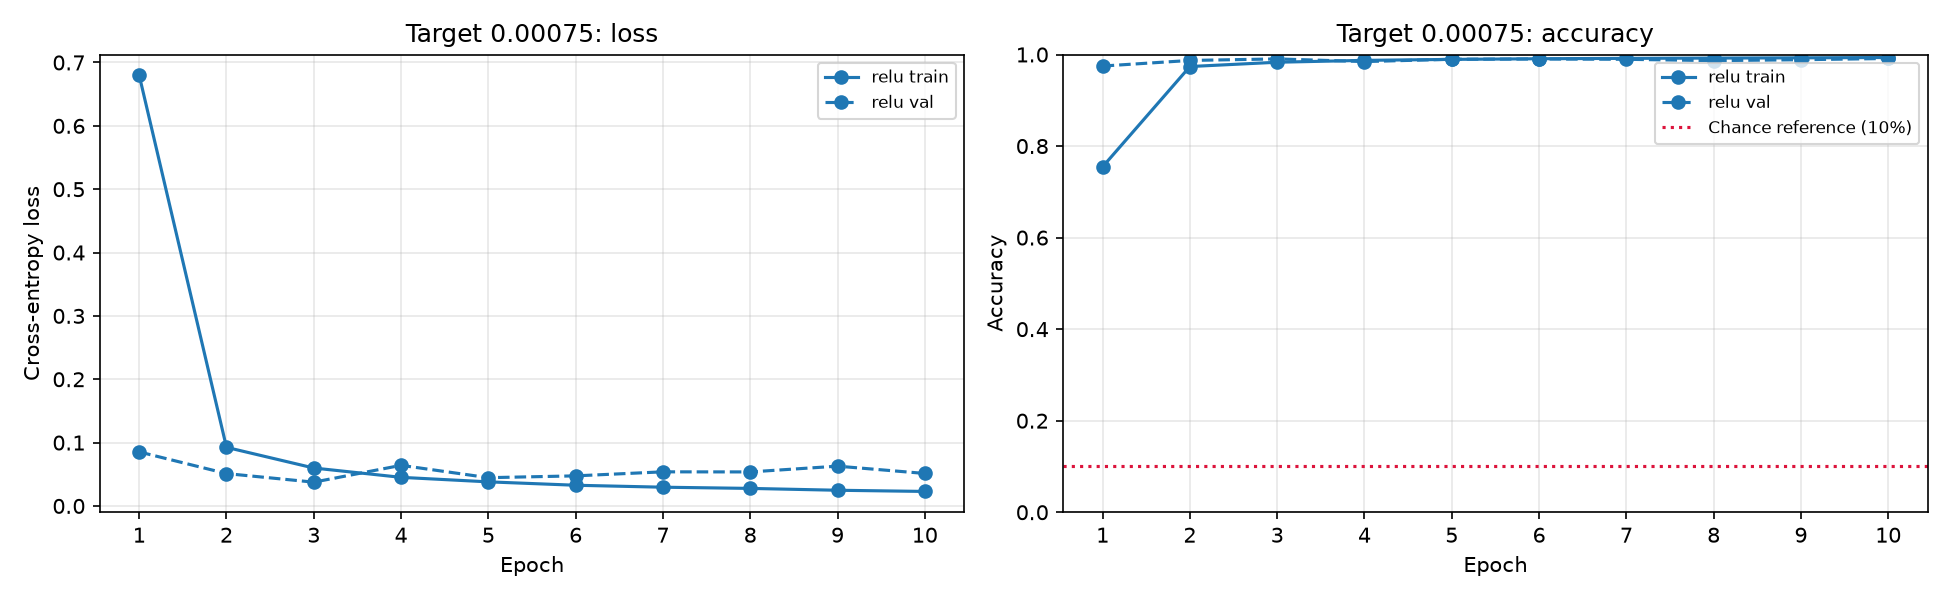

### RELU · target 0.00075 · 20261030_172301_1d257a0d

Selected minimum-loss checkpoint: epoch 3, accuracy 99.04%, loss 0.037559
Peak observed accuracy: 99.13%, epoch 10; peak weights may not be retained.


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_l2_penalty,train_objective,learning_rate_first,learning_rate_last,optimizer_steps_completed
0,1,0.679784,0.085310,0.754689,0.974762,0.001967,0.681751,1.298701e-07,0.00075,5775
1,2,0.092507,0.051095,0.973718,0.987024,0.005321,0.097828,7.500000e-04,0.00075,11550
2,3,0.059880,0.037559,0.983098,0.990357,0.007979,0.067859,7.500000e-04,0.00075,17325
3,4,0.045162,0.064106,0.987213,0.984524,0.010051,0.055213,7.500000e-04,0.00075,23100
4,5,0.038042,0.044631,0.989334,0.989643,0.011987,0.050029,7.500000e-04,0.00075,28875
5,6,0.032686,0.047496,0.990771,0.990119,0.013505,0.046190,7.500000e-04,0.00075,34650
6,7,0.029591,0.053858,0.991553,0.989524,0.014893,0.044484,7.500000e-04,0.00075,40425
7,8,0.027688,0.053707,0.992210,0.986548,0.016016,0.043704,7.500000e-04,0.00075,46200
8,9,0.024781,0.062820,0.992765,0.988571,0.016983,0.041764,7.500000e-04,0.00075,51975
9,10,0.022910,0.051299,0.993409,0.991310,0.017862,0.040772,7.500000e-04,0.00075,57750


<Figure size 1200x400 with 2 Axes>

<Figure size 800x800 with 1 Axes>

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
9,838,825,13,0.984487,0.984487,0.984487,0.996905
7,880,874,6,0.978723,0.993182,0.985900,0.997024
5,759,752,7,0.984293,0.990777,0.987525,0.997738
4,814,804,10,0.987715,0.987715,0.987715,0.997619
3,870,857,13,0.996512,0.985057,0.990751,0.998095
8,813,802,11,0.996273,0.986470,0.991347,0.998333
6,827,822,5,0.990361,0.993954,0.992154,0.998452
2,835,826,9,0.995181,0.989222,0.992192,0.998452
1,937,932,5,0.994664,0.994664,0.994664,0.998810


Actual digit 3: 13 misclassified validation images
Showing 10 of 13 errors (limit 10)


<Figure size 1280x380 with 16 Axes>

Actual digit: 1 | Predicted digit: 1


,Logit,Probability
Digit,,
0,-18.323397,7.997865e-14
1,11.833553,9.999334e-01
2,-11.557794,6.938069e-11
3,-13.873089,6.850436e-12
4,2.212832,6.633529e-05
5,-11.380469,8.284164e-11
6,-6.841135,7.756342e-09
7,-3.391703,2.441892e-07
8,-9.673459,4.566618e-10


In [11]:
experiments = importlib.reload(experiments)
experiments.refresh_helpers()
experiments.show_augmented_comparison(SELECTED_RUNS)
if FOLLOWUP_DIRECTORY is not None:
    experiments.show_results(FOLLOWUP_DIRECTORY)

for directory in (SECTION_4_DIRECTORY, SECTION_5_DIRECTORY, SECTION_6_DIRECTORY):
    if directory is not None:
        experiments.show_results(directory)


## Error investigation — saved 99.14% winner

Use run `20261030_143937_9823b3b6`: conventional augmented ReLU, LR0.00075, selected epoch3 by minimum validation loss. This is the best saved winner from the three-epoch comparison, not the latest regularization run. The next cell reuses saved logits/labels and verifies exact alignment with original upright validation images and stable source-row IDs. No inference or training. Up to eight misses per true digit are shown in validation order; fewer available means fewer shown. Confidence is softmax model probability, not calibrated certainty. Inspect whether misses look ambiguous, unusual, clipped or recognizable; do not assume all are intrinsically hard.


### Error investigation — 20261030_143937_9823b3b6 · selected epoch 3

Saved checkpoint: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/models/bespoke28_relu_20261030_143937_9823b3b6_best.pt
Selection: saved run, minimum validation loss; accuracy 99.14%.
Confidence is model softmax probability, not calibrated certainty. Row IDs are zero-based source CSV data rows.


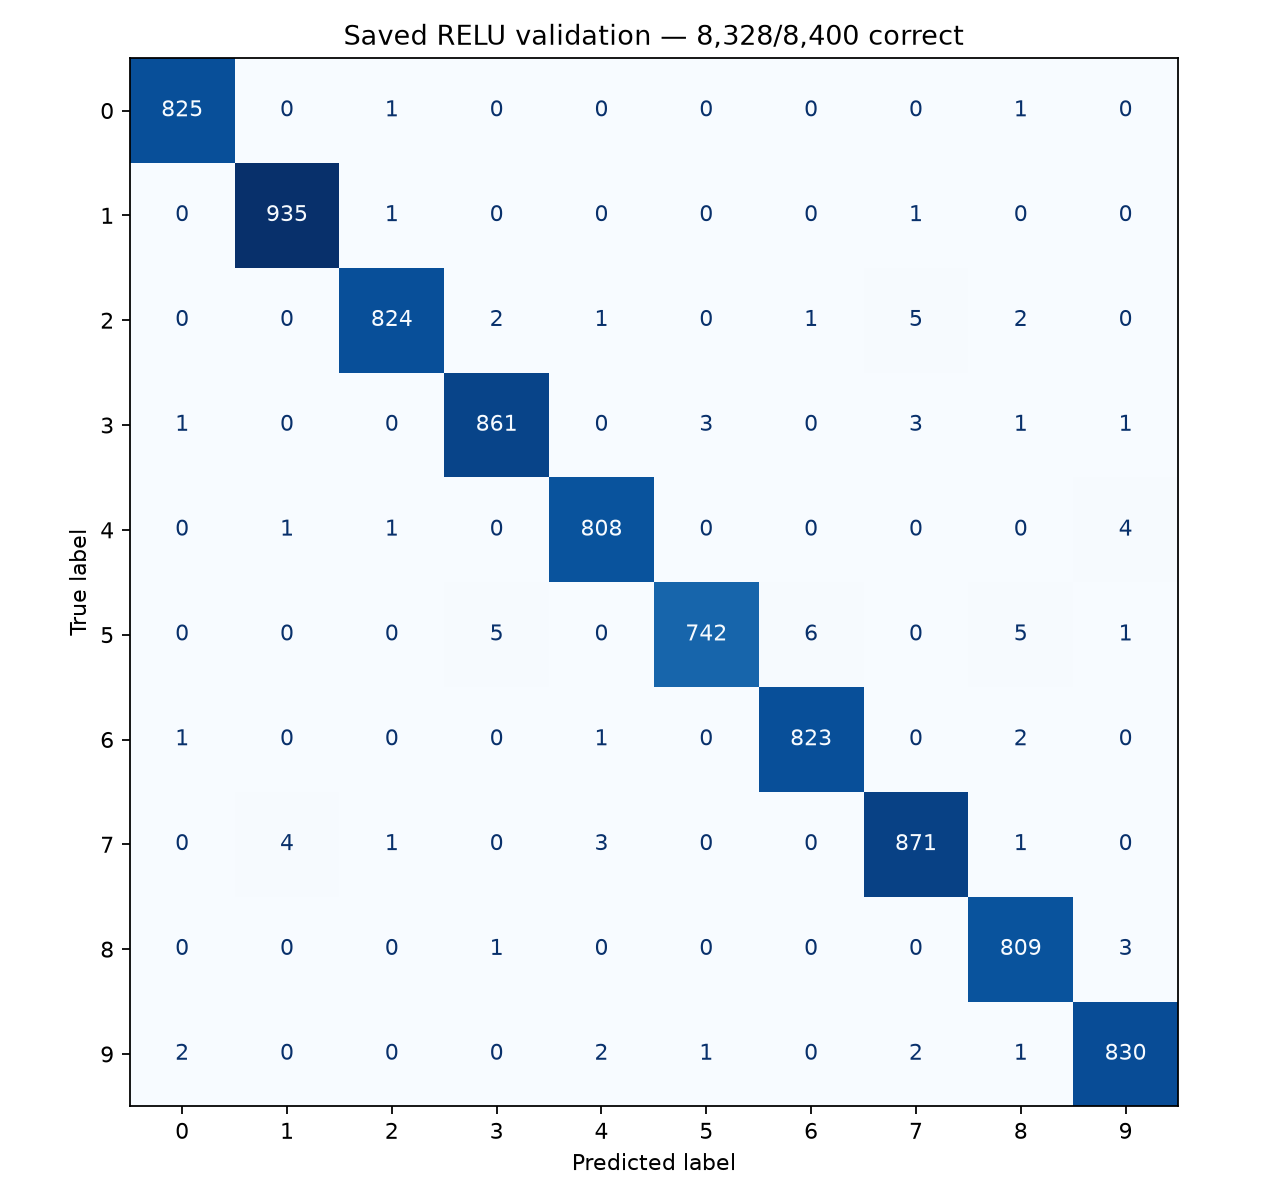

,Support,Correctly Predicted,Errors,Precision,Recall,F1
Digit,,,,,,
0,827,825,2,0.995175,0.997582,0.996377
1,937,935,2,0.994681,0.997866,0.996271
2,835,824,11,0.995169,0.986826,0.990980
3,870,861,9,0.990794,0.989655,0.990224
4,814,808,6,0.991411,0.992629,0.992020
5,759,742,17,0.994638,0.977602,0.986047
6,827,823,4,0.991566,0.995163,0.993361
7,880,871,9,0.987528,0.989773,0.988649
8,813,809,4,0.984185,0.995080,0.989602


,true_digit,predicted_digit,errors
18,5,6,6
7,2,7,5
17,5,3,5
19,5,8,5
16,4,9,4
24,7,1,4
10,3,5,3
11,3,7,3
26,7,4,3
29,8,9,3


,predicted_confidence,count,errors,accuracy,mean_confidence
0,<50%,27,12,0.555556,0.433036
1,50–<70%,59,19,0.677966,0.605235
2,70–<90%,104,18,0.826923,0.817435
3,90–<99%,333,16,0.951952,0.966714
4,99–100%,7877,7,0.999111,0.999683


,validation_index,source_row_index,csv_line_number,true_digit,predicted_digit,confidence,true_class_probability,top_two_margin,correct
7322,7322,24477,24479,3,5,0.999993,0.000005,0.999988,False
1022,1022,37887,37889,9,8,0.999975,0.000019,0.999956,False
415,415,37290,37292,9,0,0.999948,0.000032,0.999916,False
3266,3266,5747,5749,8,9,0.999554,0.000010,0.999155,False
8037,8037,27478,27480,6,8,0.997007,0.002842,0.994165,False
2197,2197,3436,3438,5,3,0.993655,0.006304,0.987351,False
3498,3498,16220,16222,3,9,0.992543,0.001562,0.989715,False
1517,1517,41294,41296,5,8,0.989129,0.003822,0.985307,False
3097,3097,7725,7727,7,1,0.988681,0.004196,0.984485,False
3255,3255,33386,33388,9,7,0.987654,0.010267,0.977387,False


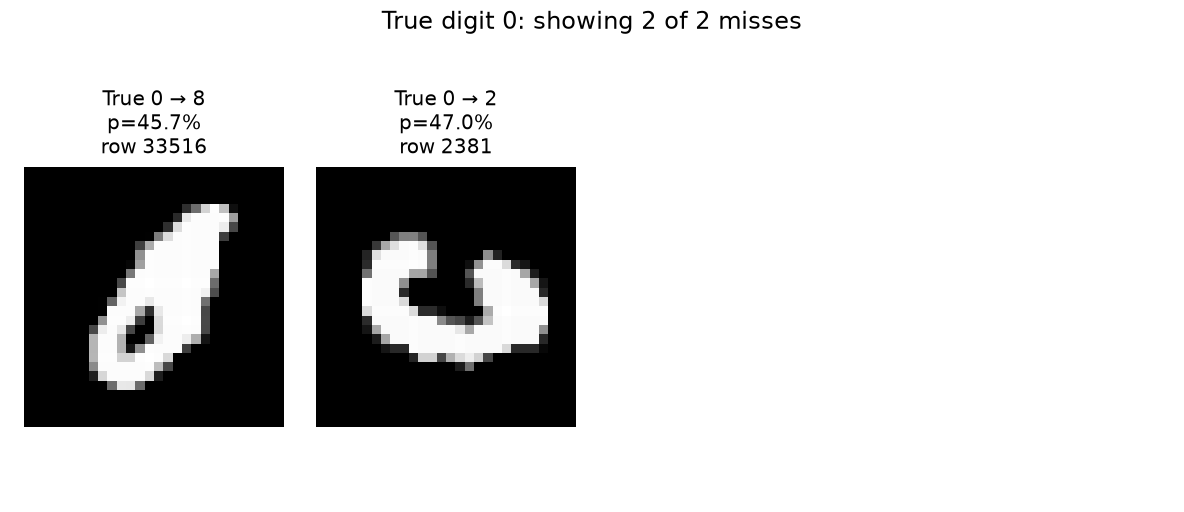

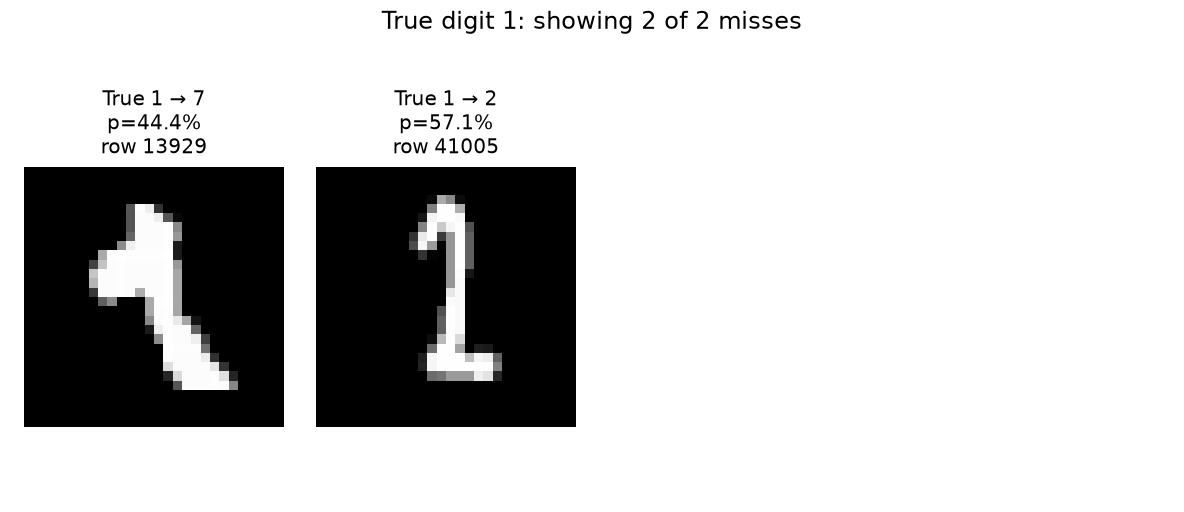

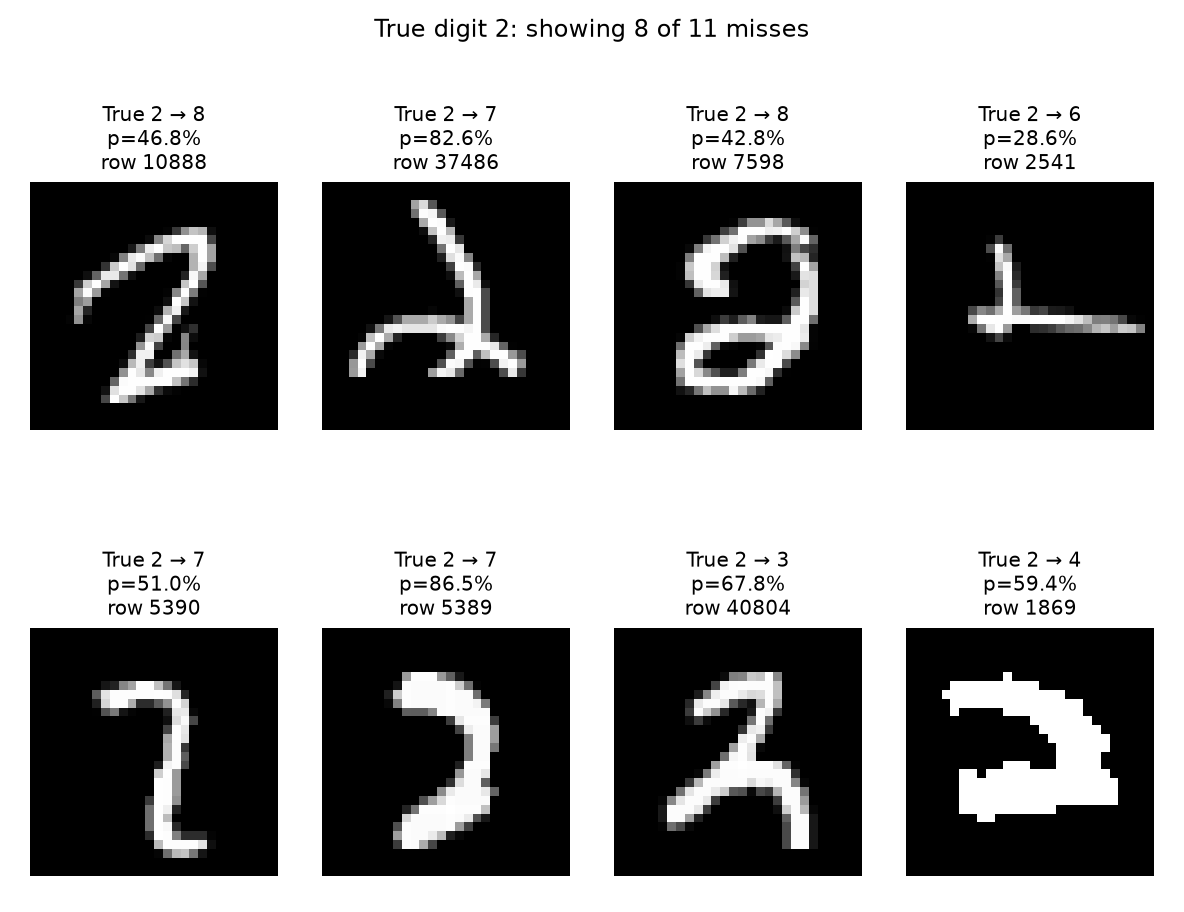

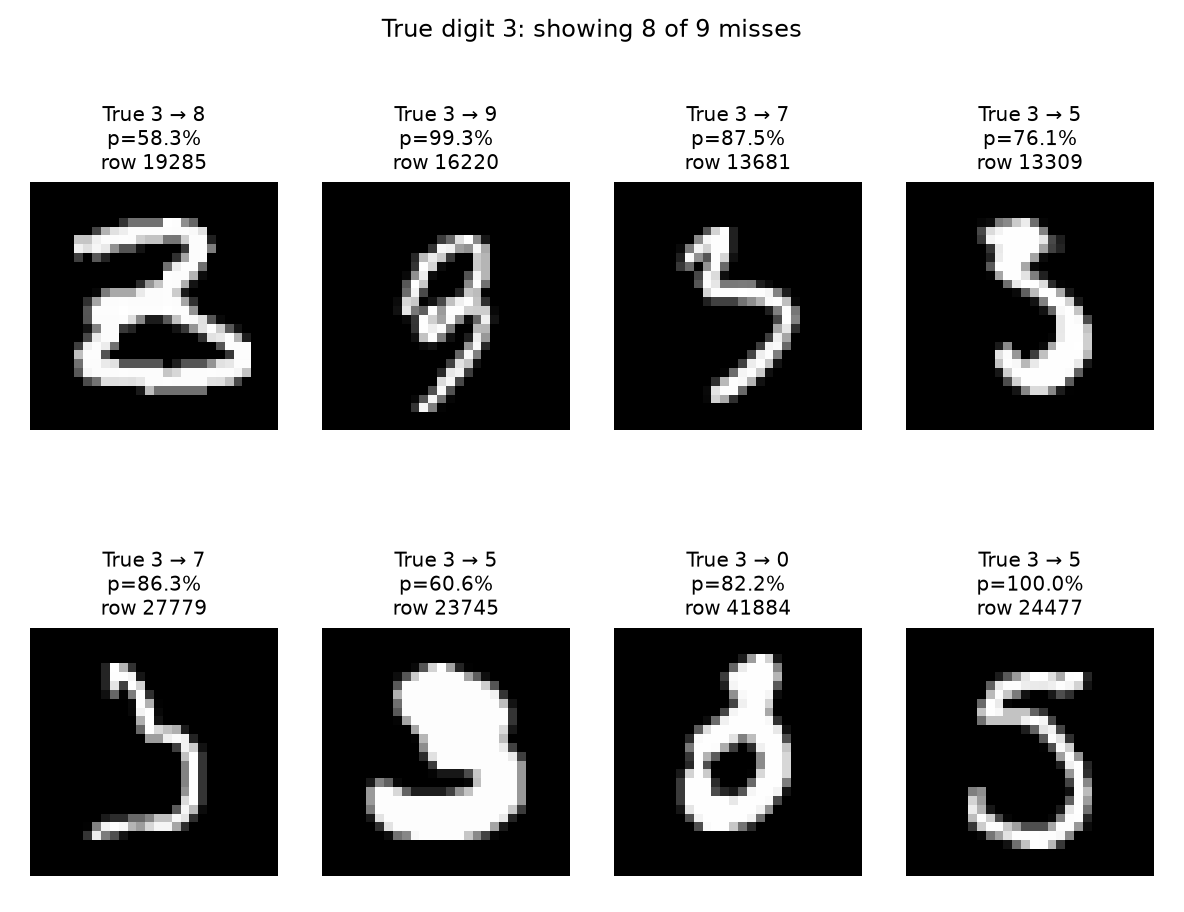

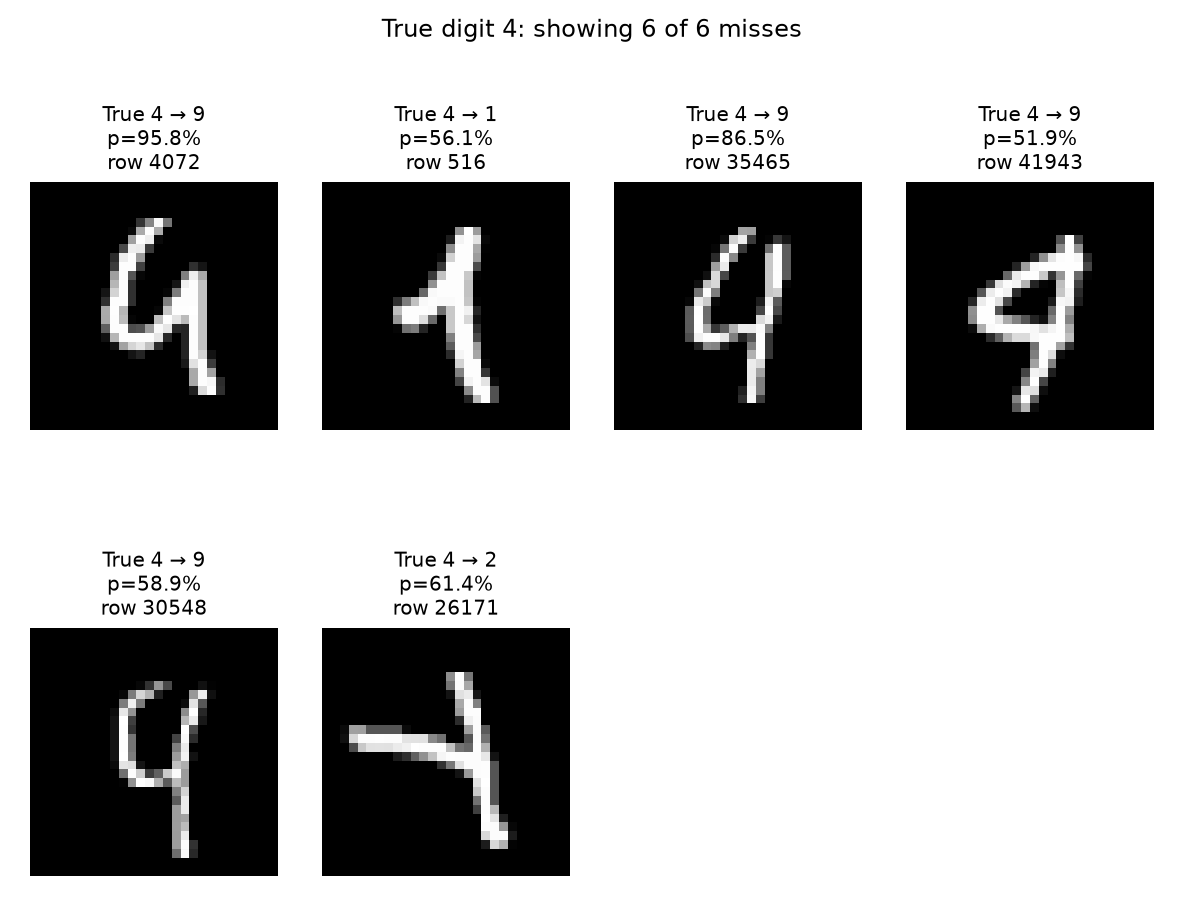

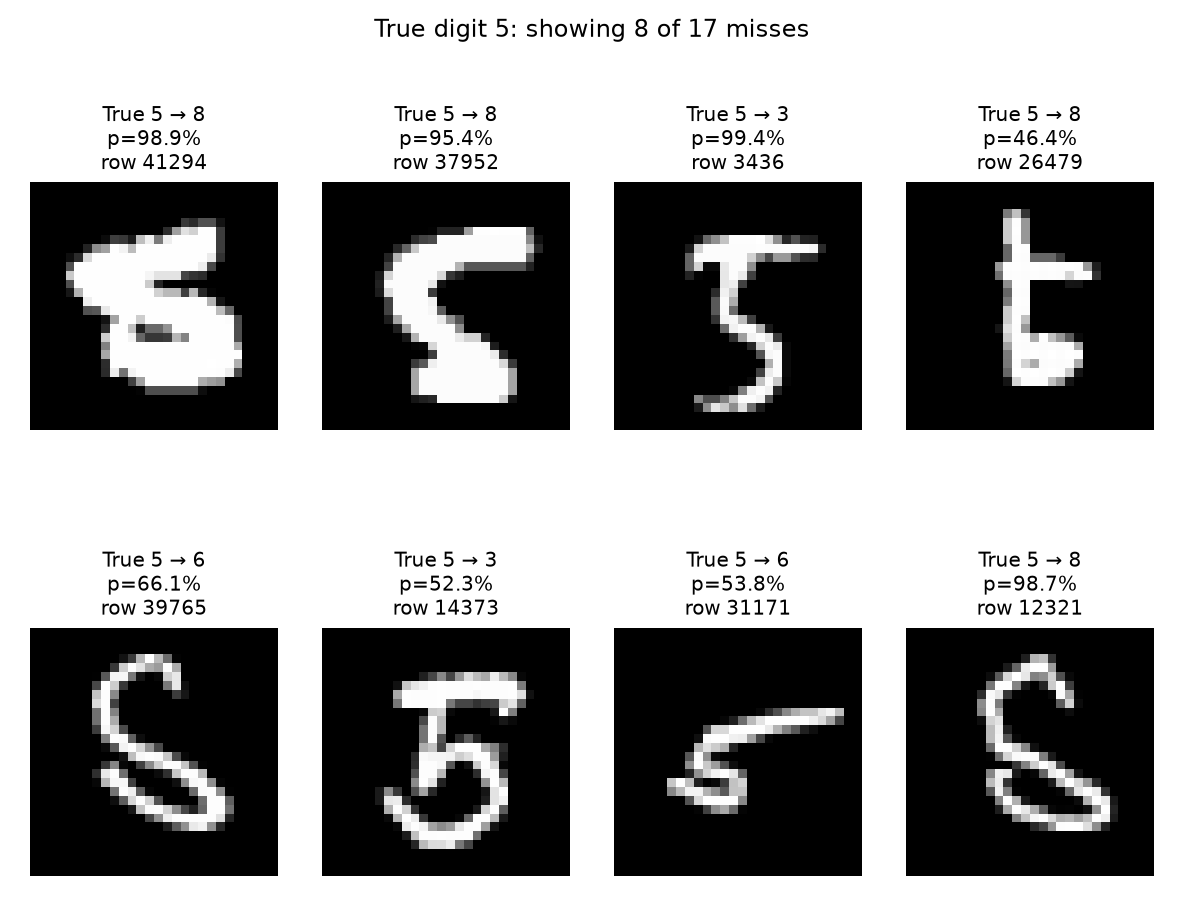

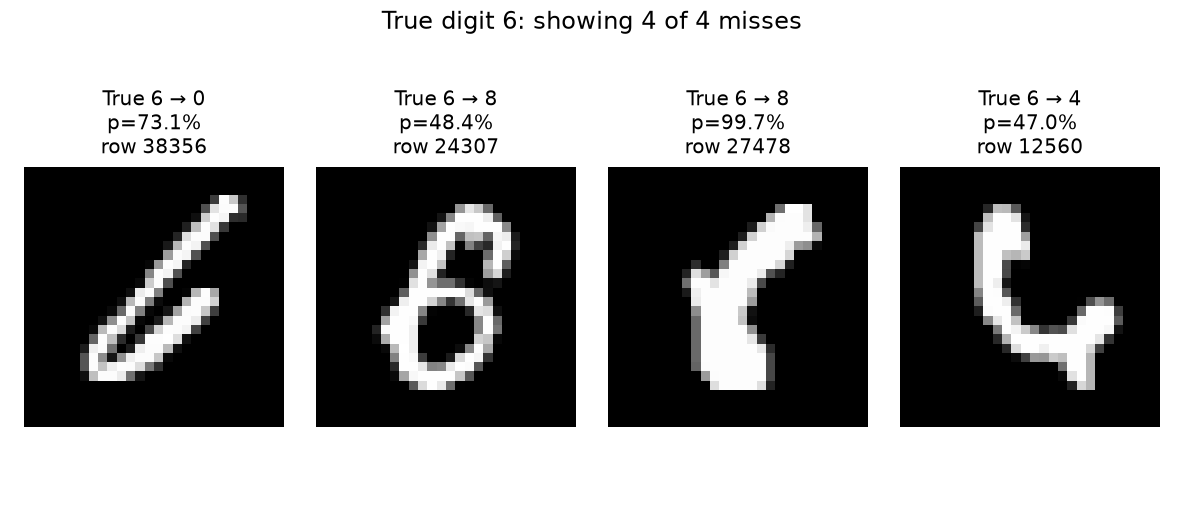

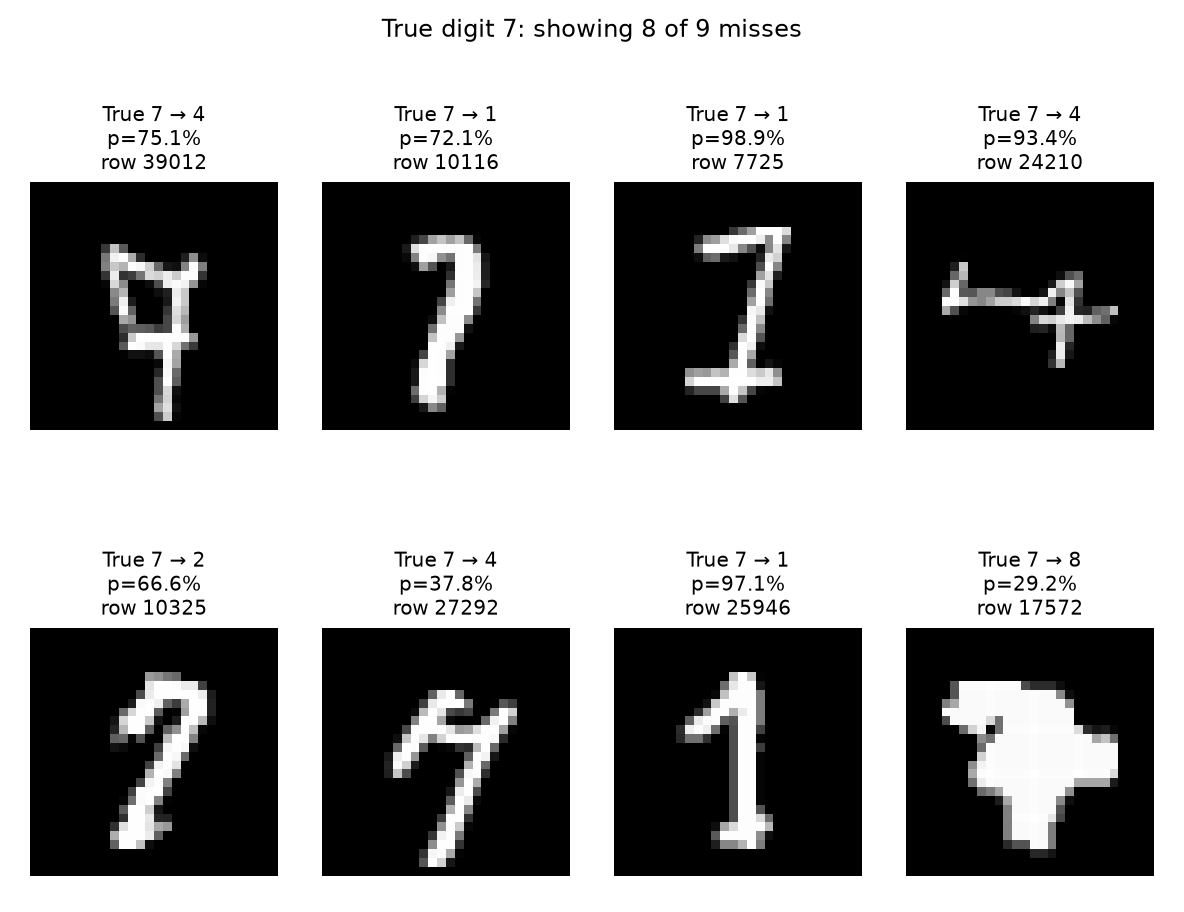

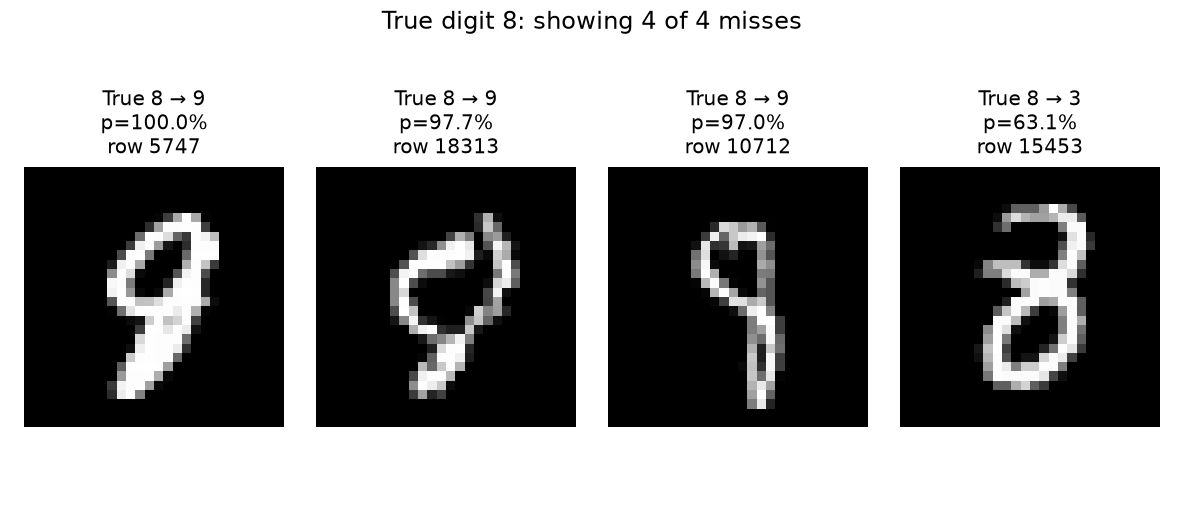

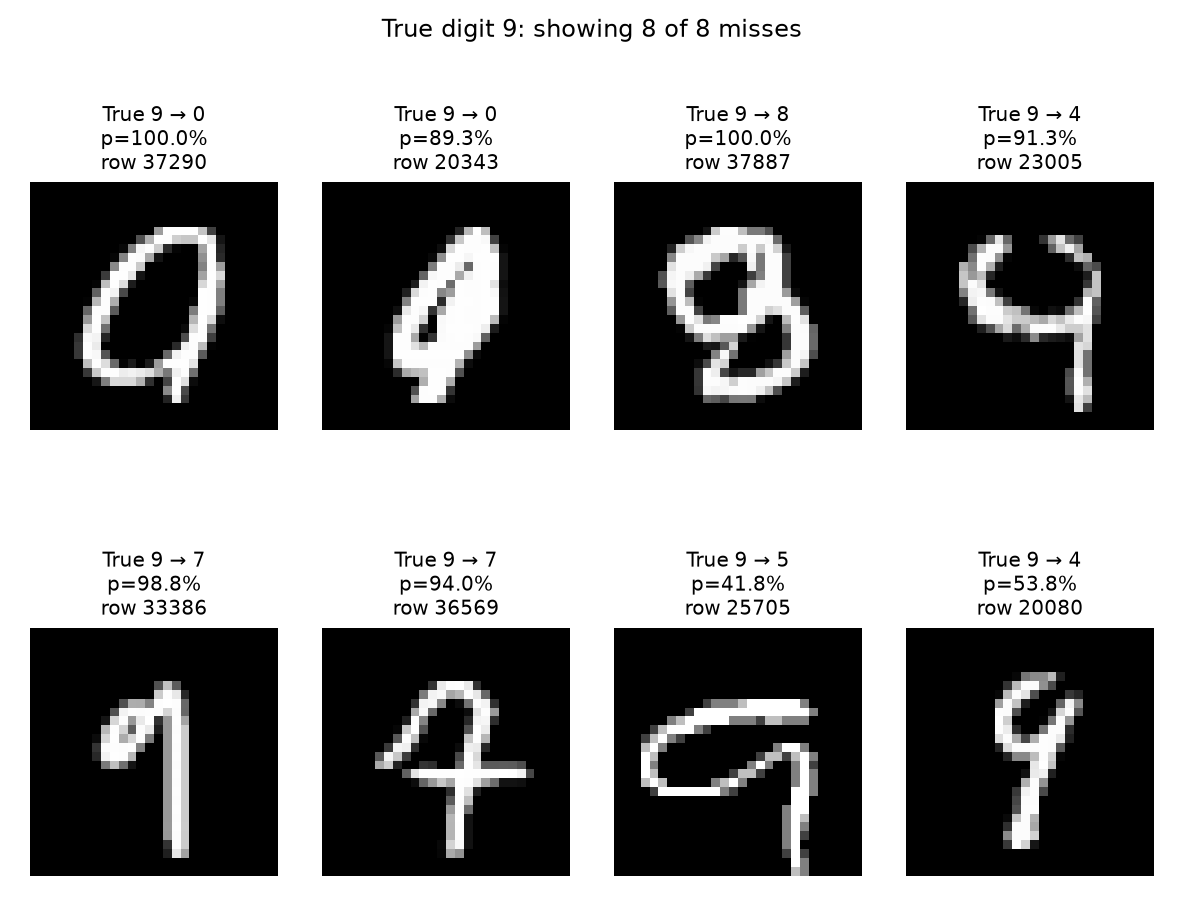

In [12]:
from scripts.model import digit_model_metrics as error_metrics
error_metrics = importlib.reload(error_metrics)
WINNING_VALIDATION_ARTIFACT = project_root / "data/validation_outputs/bespoke28_relu_20261030_143937_9823b3b6_validation.pt"
ERROR_REPORT_DIRECTORY = error_metrics.investigate_saved_errors(
    WINNING_VALIDATION_ARTIFACT, max_per_digit=8,
)
